# Quantum Metal A.4 — full chip: six qubits, a tunable coupler and a multiplexed north feedline (Quantcore PDK rebuild)

**What the chip is.** The full-chip example of Qiskit Metal,
`docs/circuit-examples/full-design-flow-examples/A.4-Full-chip-design.ipynb` (© IBM / Qiskit Metal contributors,
Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>; spec `docs/designs/metal/A4_full_chip.md`), which
the tutorial calls a teaching layout whose "resonator lengths are only roughly chosen". `Q_Main`, a
`TransmonPocket6` with six connection pads, is the hub: five λ/2 buses (6.0–7.6 mm) go to `Q1`, `Q2`
(`TransmonCrossFL` with flux lines, joined by the `TunableCoupler01` `Tune_C_Q12`) and to `Q3`, `Q4`, `Q5`
(`TransmonPocket6`, chained by two more buses). `Q_Main` is read out through a `CapNInterdigital` series capacitor,
`Q1`, `Q2` and the coupler through `LaunchpadWirebondCoupled` pads (λ/2 each); `Q3`–`Q5` are multiplexed on a north
feedline through a `CoupledLineTee` (λ/4) and two `CapNInterdigitalTee`s (λ/2). Three 5/3 µm flux lines (Q1, Q2,
coupler) and eleven launchpads. We distribute the rebuild under GPL-3.0.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the tutorial's own options, but the chip, the
stack, the junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal example | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 11 × 8 mm centred on (0, −0.5 mm) | the source's chip grown by 0.6 mm on every side (box `(-600, -600, 11600, 8600)`, so the corner launchpads and the north feedline clear the frame's marker areas), with the QCT die frame |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | 11 `LaunchpadWirebond(Coupled)`s 840–850 µm in from the die edge | the same pads, moved to **100 µm** (`frame.pad_edge`) from the south / west / east edges (PDK pad rule) |
| junctions | Metal junction lines, `hfss_inductance` 14 nH (pockets) / 10 nH (crosses, coupler) | Quantcore Nb/AlOx/Nb trilayer junctions: `Q_Main` sized for the tutorial's f_q 4.96 GHz (R_n ≈ 98 kΩ, flagged); `Q3`–`Q5` PDK nominal; `Q1`, `Q2`, the coupler a PDK SQUID |
| cheese | **yes**: the notebook exports GDS with Metal's default cheese (25 µm squares every 100 µm), `no_cheese.buffer` 50 µm | the original's Metal rule, drawn by the build (chip `cheese` = `metal_cheese_rule(buffer=50)`) |
| routes | `RouteMeander` buses and readouts, `RoutePathfinder` flux lines | qcc meanders and `cpw` routes on the same pins with the same total lengths, fillet 99 µm |
| placement | as drawn | centred in x; in y pinned by the edge pads (step 7) |

**Kept exactly:** every component with the tutorial's options, positions and orientations — the `TransmonPocket6`
connection pads (`loc_W` / `loc_H`, pad width and gap), the `TransmonCrossFL` claws (`connector_location`,
`claw_length` 95 µm), `TunableCoupler01` (`c_width` 500 µm, rotated 90°), the tees (`coupling_length` 200 µm
shorted; finger counts 8 / 11, finger lengths 0 / 50 µm), the launchpads (5/3 µm traces on the flux pads); every
route's end pins and total length (buses 6000 … 7600 µm, readouts 5000 … 6800 µm), the 99 µm fillet, and the three
flux-line paths (Metal's `RoutePathfinder` results: 4582, 3306 and 3954 µm before the pads moved).

**Simplified:** the qcc router puts each meander on one straight segment of a path given by waypoints (Metal's
`RouteMeander` meanders along the whole route with its `lead` / `asymmetry` / jog options), so the meander
footprints differ from the tutorial's picture; the waypoints keep all routes apart. The Q2 flux line's corners are
moved by up to 85 µm (Metal's 175 µm lead is too short for two 99 µm fillets in the qcc router).

**Assumed coupling:** the coupler island's ends face the cross arms of `Q1` and `Q2`; no route carries this, so it
is declared with `d.couple`, C ≈ 6 fF each from a coplanar-strip estimate (90 µm facing length, 37 µm gap). The
Q3D C-matrix of the `Q1_TC_Q2` group replaces it.

The notebook goes step by step: PDK → die → pads → components → routes → centring → DRC → netlist → LOM →
FEM job → results back → one change re-simulated → fab export → snapshots → summary.

## 1 · Setup

The imports, the output folder and the `LIVE` switch: with KLayout open (the default), every step below is pushed to
the KLayout window as you run it; with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common`
holds the small helpers the design notebooks share (tables, snapshots, the PDK placement and fab helpers).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement and fab helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
from quantcore_circuits.circuit.bridges import size_junction
from quantcore_circuits.lom import estimates as est

## 2 · The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the grown 12.2 × 9.2 mm box gets the QCT frame; the eleven launchpads go 100 µm from their edges; every qubit and the coupler get a trilayer junction or SQUID; the cheese is the original's (Metal's GDS cheese), drawn by the build instead of the PDK band.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws the **QCT frame** on it: L
dicing markers in the four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary
(100/0) and the device ID `name_chip` on a free edge (it is optional). Metal centres this chip on (0, −0.5 mm), so
every Metal position is shifted by `(X0, Y0)` (`P(x, y)` does it); the box is the source's 11 × 8 mm grown by
0.6 mm per side so the corner launchpads clear the 500 µm marker areas.

**Cheese: the original's.** The source exports its GDS with Metal's cheese on (step 14), so the original's cheese wins over the PDK band: `chip={"cheese": metal_cheese_rule(buffer=50)}` hands the build Metal's rule (25 µm squares every 100 µm, 50 µm clear of every etched shape, none within 200 µm of the die edge), and the build draws it instead of the band (`_common.metal_cheese_rule`).

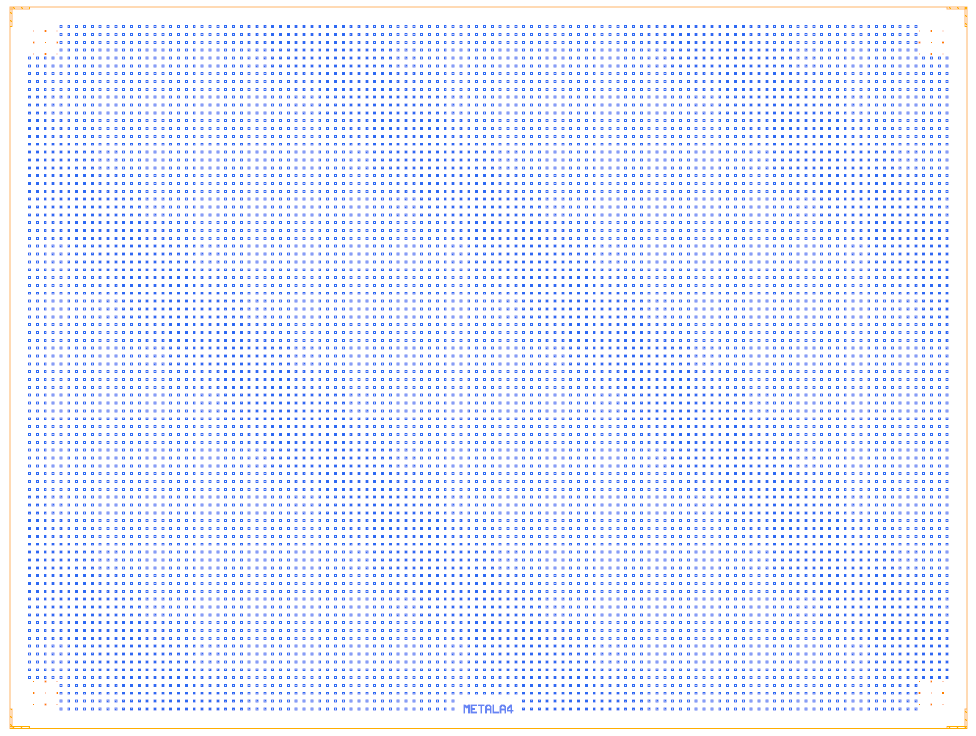

WindowsPath('examples/designs/metal/a4_full_chip_step_die.png')

In [4]:
d = Designer("a4_full_chip", box=(-600, -600, 11600, 8600), chip={"name_chip": "MetalA4", "cheese": metal_cheese_rule(buffer=50)},
             live=LIVE)
X0, Y0 = 5500, 4500                              # Metal's 11 × 8 mm chip is centred on (0, −0.5 mm)
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
rebuild(d)                                       # build the empty die (a no-op when LIVE: it is already built)
snap(d, OUT / "a4_full_chip_step_die.png", size=(976, 736), width=450)

## 4 · Pads: the PDK pad rule

The tutorial's eleven launchpads sit 840–850 µm in from the edges of this die: four on the south edge (the Q_Main
readout, the Q1 flux line and readout, the coupler flux line), four on the west edge (the coupler and Q2 readouts,
the Q2 flux line, the north feedline input) and the feedline output on the east edge. In the Quantcore PDK the outer
edge of every bond pad's etch sits **`frame.pad_edge` = 100 µm from the die edge**, whatever the source did:
`edge="s"` / `"w"` / `"e"` slides each pad perpendicular to its edge until it is there; its position along the
edge is kept, so every line still arrives on the pad's axis and only gets longer. The three flux-line pads keep the
5/3 µm trace of the flux lines; the readout pads of Q1, Q2 and the coupler are the capacitively coupled
`LaunchpadWirebondCoupled`.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| Launch_QMain_Read | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| Launch_Q1_FL | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| Launch_Q1_Read | `metal:LaunchpadWirebondCoupled` | s | 100.0 | ✓ |
| Launch_TuneC_FL | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| Launch_TuneC_Read | `metal:LaunchpadWirebondCoupled` | w | 100.0 | ✓ |
| Launch_Q2_Read | `metal:LaunchpadWirebondCoupled` | w | 100.0 | ✓ |
| Launch_Q2_FL | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| Launch_NW | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| Launch_NE | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |

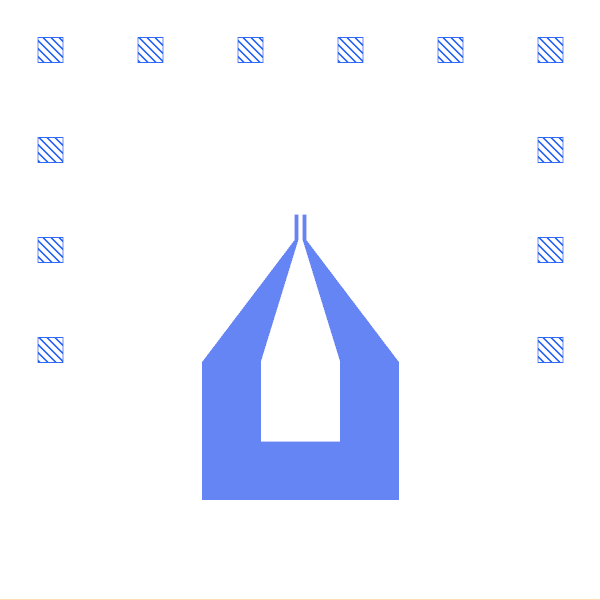

WindowsPath('examples/designs/metal/a4_full_chip_step_pads.png')

In [5]:
lp = lambda n, x, y, r, edge, cell="metal:LaunchpadWirebond", **kw: d.add(n, cell, at=P(x, y), rot=r, edge=edge, **kw)
with d.batch():
    l_qm = lp("Launch_QMain_Read", 2000, -4000, 90, "s")
    l_q1fl = lp("Launch_Q1_FL", 0, -4000, 90, "s", trace_width=5, trace_gap=3)
    l_q1r = lp("Launch_Q1_Read", -2000, -4000, 90, "s", "metal:LaunchpadWirebondCoupled")
    l_tcfl = lp("Launch_TuneC_FL", -4000, -4000, 90, "s", trace_width=5, trace_gap=3)
    l_tcr = lp("Launch_TuneC_Read", -5000, -3000, 0, "w", "metal:LaunchpadWirebondCoupled")
    l_q2r = lp("Launch_Q2_Read", -5000, -1000, 0, "w", "metal:LaunchpadWirebondCoupled")
    l_q2fl = lp("Launch_Q2_FL", -5000, 1000, 0, "w", trace_width=5, trace_gap=3)
    l_nw = lp("Launch_NW", -5000, 3000, 0, "w")
    l_ne = lp("Launch_NE", 5000, 3000, 180, "e")
rebuild(d)
display(Markdown(pads_md(d)))
px, py = port_xy(d, "Launch_Q1_FL.tie")
snap(d, OUT / "a4_full_chip_step_pads.png", box=(px - 300, -600, px + 300, 0), size=(600, 600), width=300)

## 5 · Components: qubits, coupler, capacitor and tees

**Junctions first.** Every qubit gets a Quantcore Nb/AlOx/Nb trilayer junction on the PDK junction rule (Nb Δ 1.4 meV,
I_c·R_n = πΔ/2e, R_n·A 13.5 kΩ·µm² and C_J 50 fF/µm² assumed); `trilayer_junction` returns the instance parameters
and the drawn junction's L_J / C_J (for the LOM and the FEM junction port):
- `Q3`–`Q5`: the PDK nominal junction (0.5 × 0.6 µm fingers, R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF);
- `Q1`, `Q2` and the coupler (flux lines): a PDK SQUID of two 0.25 × 0.6 µm junctions (45 kΩ in parallel, L_J
  6.73 nH at zero flux);
- `Q_Main`: the only qubit with a stated target (f_q 4.96 GHz, Metal's Q3D + LOM result): `size_junction` solves the
  junction for it on the pocket's C_Σ (54.9 fF from this design's LOM before the rebuild). The small pocket needs
  L_J ≈ 14.6 nH: a 0.23 µm finger, **R_n ≈ 98 kΩ, outside the 40–50 kΩ window**. That is flagged (DRC `pdk_rn`),
  not retuned: the value is the source's.

**The components** keep the tutorial's options: the six-pad `TransmonPocket6`s (`pads6` packs `loc_W`, `loc_H`, pad
width and gap per connection pad), the two `TransmonCrossFL`s with their claws and flux lines, the
`TunableCoupler01` between them, the series capacitor of the Q_Main readout and the three north-feedline tees.

Q_Main: L_J 14.64 nH, C_J 6.9 fF, R_n 99 kΩ, fingers 0.23 × 0.6 µm; R_n 98.6 kΩ is outside the process window 40–50 kΩ (f_q 4.96 GHz with C_Σ 61.7 fF needs E_J/h 11.1 GHz)
Q3–Q5: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0} | Q1, Q2, coupler: {'junction_type': 'Quantcore Squid', 'junction_params': {'lj_nH': 6.7344}} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}
Q_Main ports: ['bus_01', 'bus_02', 'bus_03', 'bus_04', 'bus_05', 'readout', 'squid_a', 'squid_b']
Q1 ports: ['bus_01', 'flux_line', 'readout', 'squid_a', 'squid_b'] | coupler ports: ['Control', 'Flux', 'squid_a', 'squid_b']


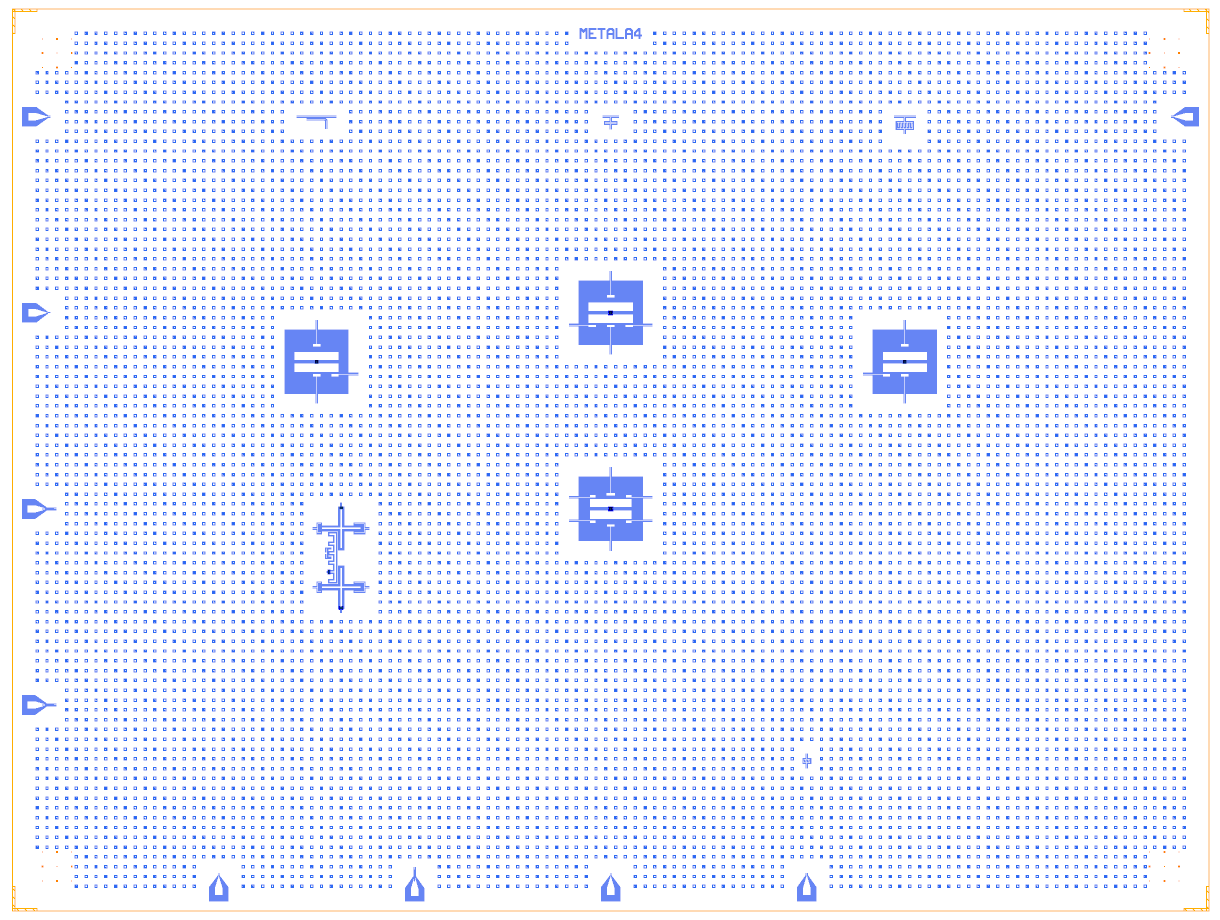

WindowsPath('examples/designs/metal/a4_full_chip_step_parts.png')

In [6]:
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket6")
SQ_PARAMS, SQUID = trilayer_junction("metal:TransmonCrossFL", lj_nH=JUNCTION["Lj_nH"], squid=True)
SIZED_QM = size_junction(4.96, 54.9, c_includes_junction=False)    # C_Σ 54.9 fF without the junction (pre-rebuild LOM)
QM_PARAMS, JJ_QM = trilayer_junction("metal:TransmonPocket6", lj_nH=SIZED_QM.lj_nH)
print(f"Q_Main: L_J {JJ_QM['Lj_nH']} nH, C_J {JJ_QM['Cj_fF']} fF, R_n {SIZED_QM.rn_kohm:.0f} kΩ, fingers "
      f"{SIZED_QM.finger_width} × {SIZED_QM.second_finger_width} µm; " + "; ".join(SIZED_QM.notes))
print("Q3–Q5:", JJ_PARAMS, JUNCTION, "| Q1, Q2, coupler:", SQ_PARAMS, SQUID)
pads6 = lambda **kw: {k: dict(zip(("loc_W", "loc_H", "pad_width", "pad_gap"), v)) for k, v in kw.items()}
with d.batch():
    qm = d.add("Q_Main", "metal:TransmonPocket6", at=P(0, -1000), pad_width=425, pocket_height=650, junction=JJ_QM,
               **QM_PARAMS, connection_pads=pads6(readout=(0, -1, 80, 50), bus_01=(-1, -1, 60, 10),
                                                 bus_02=(-1, 1, 60, 10), bus_03=(0, 1, 90, 30),
                                                 bus_04=(1, 1, 60, 10), bus_05=(1, -1, 60, 10)))
    q1 = d.add("Q1", "metal:TransmonCrossFL", at=P(-2750, -1800), junction=SQUID, **SQ_PARAMS, fl_options={},
               connection_pads={"bus_01": {"connector_location": "180", "claw_length": 95},
                                "readout": {"connector_location": "0"}})
    q2 = d.add("Q2", "metal:TransmonCrossFL", at=P(-2750, -1200), rot=180, junction=SQUID, **SQ_PARAMS, fl_options={},
               connection_pads={"bus_02": {"connector_location": "0", "claw_length": 95},
                                "readout": {"connector_location": "180"}})
    tc = d.add("Tune_C_Q12", "metal:TunableCoupler01", at=P(-2810, -1500), rot=90, c_width=500, junction=SQUID,
               **SQ_PARAMS)
    q3 = d.add("Q3", "metal:TransmonPocket6", at=P(-3000, 500), junction=JUNCTION, **JJ_PARAMS,
               connection_pads=pads6(bus_03=(0, -1, 80, 15), bus_q3_q4=(1, -1, 80, 15), readout=(0, 1, 80, 50)))
    q4 = d.add("Q4", "metal:TransmonPocket6", at=P(0, 1000), junction=JUNCTION, **JJ_PARAMS,
               connection_pads=pads6(bus_04=(0, -1, 80, 15), bus_q3_q4=(-1, -1, 80, 15), bus_q4_q5=(1, -1, 80, 15),
                                     readout=(0, 1, 80, 50)))
    q5 = d.add("Q5", "metal:TransmonPocket6", at=P(3000, 500), junction=JUNCTION, **JJ_PARAMS,
               connection_pads=pads6(bus_05=(0, -1, 80, 15), bus_q4_q5=(-1, -1, 80, 15), readout=(0, 1, 80, 50)))
    cap = d.add("Read_Q_Main_Cap", "metal:CapNInterdigital", at=P(2000, -3500))
    t3 = d.add("Q3_Read_T", "metal:CoupledLineTee", at=P(-3000, 3000), coupling_length=200, open_termination=False)
    t4 = d.add("Q4_Read_T", "metal:CapNInterdigitalTee", at=P(0, 3000), finger_length=0, finger_count=8)
    t5 = d.add("Q5_Read_T", "metal:CapNInterdigitalTee", at=P(3000, 3000), finger_length=50, finger_count=11)
print("Q_Main ports:", sorted(qm.ports))
print("Q1 ports:", sorted(q1.ports), "| coupler ports:", sorted(tc.ports))
snap(d, OUT / "a4_full_chip_step_parts.png", size=(1220, 920), width=480)

## 6 · Routes: buses, readouts, flux lines and the north feedline

- **Buses:** seven fixed-length meanders (λ/2 between two pads): `Q_Main` to each of `Q1`–`Q5`, and `Q3`–`Q4`,
  `Q4`–`Q5`. The waypoints give each meander its own straight to fold on (the qcc router meanders one segment), so
  all lines stay apart.
- **Readouts:** `Q_Main` through the series interdigital capacitor to its pad; `Q1`, `Q2` and the coupler's
  `Control` claw to their coupled launchpads (λ/2 each); `Q3`–`Q5` to their tees on the north feedline (`Read_Q3` is a
  λ/4 on the shorted `CoupledLineTee`, `Read_Q4` / `Read_Q5` λ/2 on the interdigital tees).
- **Flux lines:** 5/3 µm CPWs on Metal's `RoutePathfinder` paths, from the flux T-lines of `Q1`, `Q2` and the coupler
  to their pads.
- **North feedline:** four straight segments `Launch_NW` → three tees → `Launch_NE`.
- **Couplings, targets, sim groups:** the coupler island's ends face the cross arms (no route carries it), so the two
  capacitances are declared with `d.couple` from a coplanar-strip estimate; `Q_Main` gets the tutorial's target;
  the FEM boxes get margins that cut every other line once.

C(TC ↔ Q1/Q2) estimate: 5.86 fF


route lengths (µm): {'Bus_01': 6000, 'Bus_02': 6400, 'Bus_03': 6800, 'Bus_04': 7200, 'Bus_05': 7600, 'Bus_Q3_Q4': 6400, 'Bus_Q4_Q5': 6800, 'Read_Q_Main': 5600, 'Read_Q_Main_Cap_Launch': 1069, 'Read_Q1': 6800, 'Read_Q2': 5400, 'Read_TuneC': 5800, 'Flux_Line_Q1': 5322, 'Flux_Line_TuneC': 4046, 'Flux_Line_Q2': 4694, 'ML_TL_01': 2515, 'ML_TL_02': 2720, 'ML_TL_03': 2810, 'ML_TL_04': 2605, 'Read_Q3': 5000, 'Read_Q4': 5800, 'Read_Q5': 5400}


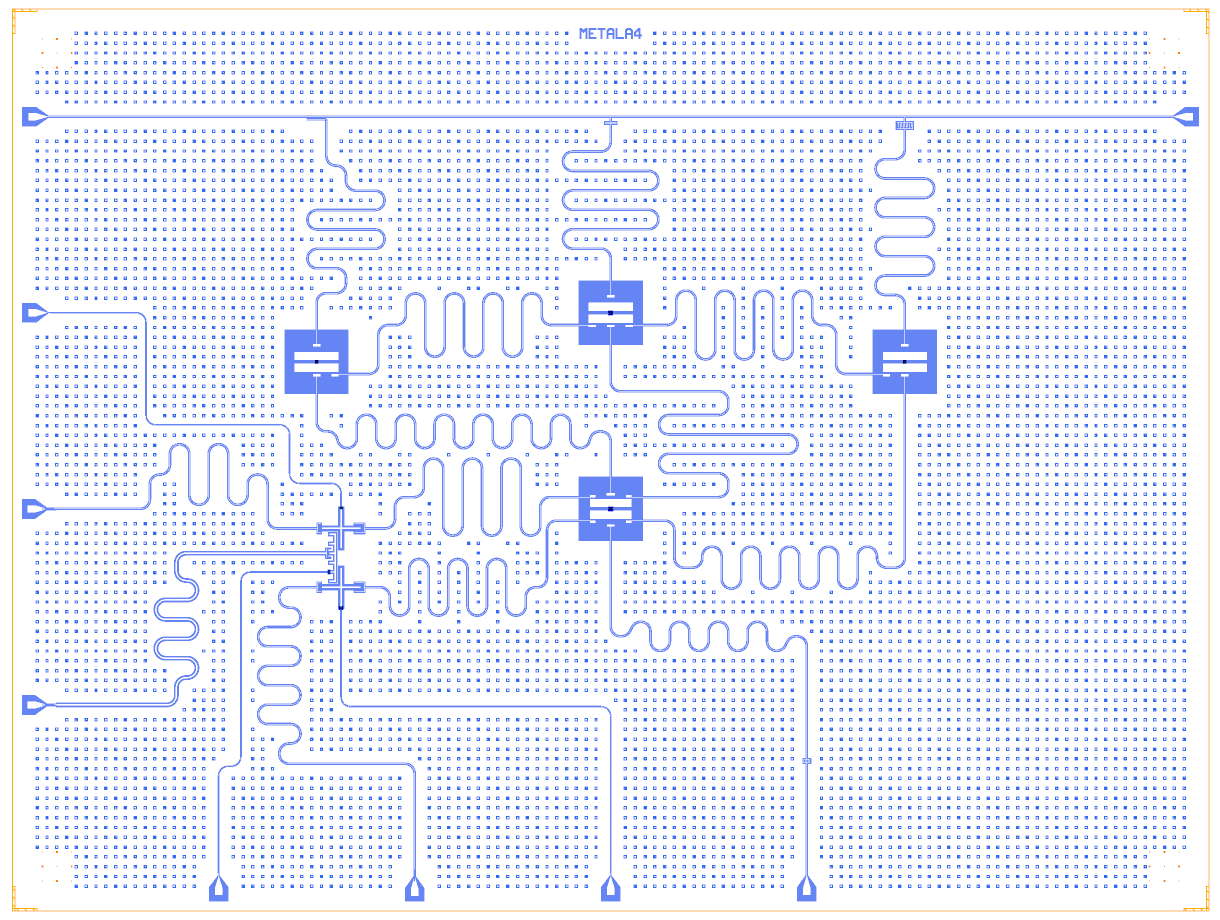

WindowsPath('examples/designs/metal/a4_full_chip_step_routes.png')

In [7]:
R = 99                                           # Metal fillet
FL = dict(a=5, b=3)                              # flux lines 5/3 µm
with d.batch():
    # buses from Q_Main (total lengths as in Metal; the meander footprints are the qcc router's)
    d.route("Bus_01", qm.bus_01, q1.bus_01, meander=6000, r=R, nodes=[(4850, 3380), (4850, 2700)])
    d.route("Bus_02", qm.bus_02, q2.bus_02, meander=6400, r=R, nodes=[(3300, 3620), (3300, 3300)])
    d.route("Bus_03", qm.bus_03, q3.bus_03, meander=6800, r=R, nodes=[(5500, 4290), (2500, 4290)])
    d.route("Bus_04", qm.bus_04, q4.bus_04, meander=7200, r=R, nodes=[(6700, 3620), (6700, 4700), (5500, 4700)]).set(meander_segment=3)
    d.route("Bus_05", qm.bus_05, q5.bus_05, meander=7600, r=R, nodes=[(6150, 3380), (6150, 2900), (8500, 2900)])
    d.route("Bus_Q3_Q4", q3.bus_q3_q4, q4.bus_q3_q4, meander=6400, r=R, nodes=[(3130, 4875), (3130, 5375)])
    d.route("Bus_Q4_Q5", q4.bus_q4_q5, q5.bus_q4_q5, meander=6800, r=R, nodes=[(7800, 5375), (7800, 4875)])
    # individual readouts (λ/2: claw / pad → coupled launchpad or series capacitor)
    d.route("Read_Q_Main", qm.readout, cap.north_end, meander=5600, r=R, nodes=[(5500, 2200), (7500, 2200)])
    d.route("Read_Q_Main_Cap_Launch", cap.south_end, l_qm.tie)
    d.route("Read_Q1", q1.readout, l_q1r.tie, meander=6800, r=R, nodes=[(2120, 2700), (2120, 900), (3500, 900)])
    d.route("Read_Q2", q2.readout, l_q2r.tie, meander=5400, r=R,
            nodes=[(2000, 3300), (2000, 3850), (800, 3850), (800, 3500)])
    d.route("Read_TuneC", tc.Control, l_tcr.tie, meander=5800, r=R, nodes=[(1070, 3048), (1070, 1500)])
    # flux lines (Metal RoutePathfinder paths)
    d.route("Flux_Line_Q1", q1.flux_line, l_q1fl.tie, r=R, nodes=[(2750, 1483), (5500, 1483)], **FL)
    d.route("Flux_Line_TuneC", tc.Flux, l_tcfl.tie, r=R, nodes=[(1728, 2856), (1728, 875), (1500, 875)], **FL)
    d.route("Flux_Line_Q2", q2.flux_line, l_q2fl.tie, r=R,
            nodes=[(2750, 3760), (2225, 3760), (2225, 4358), (760, 4358), (760, 5500)], **FL)
    # north multiplexed feedline and its three readouts
    d.route("ML_TL_01", l_nw.tie, t3.prime_start)
    d.route("ML_TL_02", t3.prime_end, t4.prime_start)
    d.route("ML_TL_03", t4.prime_end, t5.prime_start)
    d.route("ML_TL_04", t5.prime_end, l_ne.tie)
    d.route("Read_Q3", q3.readout, t3.second_end, meander=5000, r=R,
            nodes=[(2500, 5700), (2800, 5700), (2800, 7000), (2600, 7000)])
    d.route("Read_Q4", q4.readout, t4.second_end, meander=5800, r=R)
    d.route("Read_Q5", q5.readout, t5.second_end, meander=5400, r=R)
    # the coupler island ends face the qubits' cross arms (no route carries this): estimated, assumed
    # coupler island end (20 µm) facing a cross arm (20 µm) over ≈ 90 µm across ≈ 37 µm (coplanar strips)
    C_TC = round(est.coplanar_coupling(90, 20, 20, 37, est.substrate_eps(get_pdk())), 2)
    d.couple("Cg_Q1_TC", "Q1", "Tune_C_Q12", C_fF=C_TC, note="TC island end ↔ Q1 cross arm (CPS estimate)")
    d.couple("Cg_Q2_TC", "Q2", "Tune_C_Q12", C_fF=C_TC, note="TC island end ↔ Q2 cross arm (CPS estimate)")
print("C(TC ↔ Q1/Q2) estimate:", C_TC, "fF")
TARGETS = {"Q_Main": {"f_q_GHz": 4.96, "alpha_MHz": -351}}   # Metal's Q3D + LOM result (tutorial)
d.targets(**TARGETS)
# FEM boxes: margins chosen so that each box cuts every other line once (no meander lobes inside)
d.sim_group("QMain", ["Q_Main"], margin_um=150, analyses=["q3d_cmatrix"])
d.sim_group("Q1_TC_Q2", ["Q1", "Q2", "Tune_C_Q12"], margin_um=60, analyses=["q3d_cmatrix"])
for k, m in ((3, 80), (4, 100), (5, 150)):
    d.sim_group(f"Q{k}_read", [f"Q{k}", f"Read_Q{k}", f"Q{k}_Read_T"], margin_um=m, analyses=["q3d_cmatrix", "eigenmode_epr"])
rebuild(d)
print("route lengths (µm):", {k: round(v) for k, v in d.result.route_lengths().items()})
snap(d, OUT / "a4_full_chip_step_routes.png", size=(1220, 920), width=480)

## 7 · Centre the content and save

The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
(components and routes) and shifts the design so its centre is the die centre; pads given an `edge` slide back to
their 25 µm along it. Here the west and east pads span the die in x, so x is centred already. In y the content is
pinned at both ends: the four south pads sit at the bottom edge, and the north feedline ends on `Launch_NW` /
`Launch_NE`, on the west / east edges just below the top corners' 500 µm marker areas. Shifting it up by the
≈ 450 µm `center_in_die` asks for puts those two pads onto the marker areas (DRC `frame_keepout`; tried while
writing this notebook), and it does not even centre the box (the south pads slide back down). So this chip keeps the
source's vertical placement: centred in x, pinned by its pads in y (the source itself has its pads 0.5 mm from both
its bottom and top edges; only the bottom ones could move to the edge). The cell measures the offset and centres x
if it were needed. Then the design is saved: the JSON is the deliverable.

In [8]:
box = content_box(d)
x0, y0, x1, y1 = d.design.chip.box
dx, dy = round((x0 + x1) / 2 - box.center().x, 1), round((y0 + y1) / 2 - box.center().y, 1)
print(f"content box ({box.left:.0f}, {box.bottom:.0f}) – ({box.right:.0f}, {box.top:.0f}) µm; "
      f"centre − die centre ({-dx:+.0f}, {-dy:+.0f}) µm")
if abs(dx) > 50:
    translate_design(d, dx, 0.0)                 # x only: y is pinned by the pads (see above)
rebuild(d)
DESIGN = d.save(OUT / "a4_full_chip.json")
print(d, "→", DESIGN)
print("route lengths (µm):", {k: round(v) for k, v in d.result.route_lengths().items()})

content box (-500, -500) – (11500, 7598) µm; centre − die centre (-0, -451) µm
<Designer a4_full_chip: 20 instances, 22 routes, live=False> → examples\designs\metal\a4_full_chip.json
route lengths (µm): {'Bus_01': 6000, 'Bus_02': 6400, 'Bus_03': 6800, 'Bus_04': 7200, 'Bus_05': 7600, 'Bus_Q3_Q4': 6400, 'Bus_Q4_Q5': 6800, 'Read_Q_Main': 5600, 'Read_Q_Main_Cap_Launch': 1069, 'Read_Q1': 6800, 'Read_Q2': 5400, 'Read_TuneC': 5800, 'Flux_Line_Q1': 5322, 'Flux_Line_TuneC': 4046, 'Flux_Line_Q2': 4694, 'ML_TL_01': 2515, 'ML_TL_02': 2720, 'ML_TL_03': 2810, 'ML_TL_04': 2605, 'Read_Q3': 5000, 'Read_Q4': 5800, 'Read_Q5': 5400}


## 8 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here: **no errors**; `dangling_port` warnings for the junction attachment points of the qubit and
coupler cells (`squid_a` / `squid_b`, the cell draws the junction itself) and the unused claws; two `overlap`
warnings, the coupler's bounding box overlapping those of `Q1` and `Q2` (in the source the coupler sits between the
two crosses with its island ends facing their arms; the metal does not touch). **PDK design warnings**, flagged and
not retuned:
- `pdk_rn` on `Q_Main` (R_n ≈ 98 kΩ: sized for the tutorial's 4.96 GHz on a small pocket);
- nothing else: the PDK SQUIDs of `Q1`, `Q2` and the coupler are judged on their parallel R_n (45 kΩ, in the window),
  and the 95 µm `claw_length` of `Q1` / `Q2` is well short of their 200 µm arms (no `pdk_claw`).

No `pad_edge` warnings: all eleven pads are at 100 µm.

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [9]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 16 warnings · 1 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 14 | Q1.squid_a is not connected (no route or snap) |
| warning | `overlap` | 2 | Q1 and Tune_C_Q12 overlap |
| PDK design warning | `pdk_rn` | 1 | Q_Main: junction R_n 97.8 kΩ is outside the PDK window 40–50 kΩ (L_J 14.64 nH) |

| check | value |
|---|---|
| cheese | the original design's rule (drawn in the build): size 25, gap 75, rows 1000, clearance 50, edge 200 |
| content centre − die centre | (+0, -451) µm |
| junction types | Quantcore Junction × 4, Quantcore Squid × 3 |
| PDK design warnings | 1 (pdk_rn × 1) |
| pdk_rn | Q_Main: junction R_n 97.8 kΩ is outside the PDK window 40–50 kΩ (L_J 14.64 nH) |

## 9 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: `TransmonPocket6` → two floating pad nodes with the junction
between them, plus a node per connection pad; `TransmonCrossFL` → a grounded cross island with a SQUID, a node per
claw and the flux line as a control; `TunableCoupler01` → a grounded island with a SQUID, the `Control` claw as a node,
`Flux` as a control. Every bus between two pads is a λ/2 `TLres`; the readouts ending on a coupled launchpad, the
series capacitor or a `CapNInterdigitalTee` are λ/2, the shorted `CoupledLineTee` makes `Read_Q3` a λ/4 with a
hanger κ into the feedline. The two `d.couple` capacitances join the coupler island to the two cross islands.

In [10]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q_Main.", "Tune_C_Q12."))})

**31 nodes · 116 branches · 3 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `Read_Q_Main_Cap.b` | `Launch_QMain_Read.pad`, `Read_Q_Main_Cap.south_end` |
| `Launch_Q1_Read.pad` | `Launch_Q1_Read.pad` |
| `Launch_Q1_Read.tie` | `Launch_Q1_Read.tie`, `Q1.readout` |
| `Launch_TuneC_Read.pad` | `Launch_TuneC_Read.pad` |
| `Launch_TuneC_Read.tie` | `Launch_TuneC_Read.tie`, `Tune_C_Q12.Control` |
| `Launch_Q2_Read.pad` | `Launch_Q2_Read.pad` |
| `Launch_Q2_Read.tie` | `Launch_Q2_Read.tie`, `Q2.readout` |
| `Q3_Read_T.prime` | `Launch_NW.pad`, `Launch_NE.pad`, `Q3_Read_T.prime`, `Q4_Read_T.prime`, `Q5_Read_T.prime` |
| `Q_Main.island1` | `Q_Main.island1` |
| `Q_Main.island2` | `Q_Main.island2` |
| `Q_Main.readout` | `Q_Main.readout`, `Read_Q_Main_Cap.north_end` |
| `Q_Main.bus_01` | `Q_Main.bus_01`, `Q1.bus_01` |
| `Q_Main.bus_02` | `Q_Main.bus_02`, `Q2.bus_02` |
| `Q_Main.bus_03` | `Q_Main.bus_03`, `Q3.bus_03` |
| `Q_Main.bus_04` | `Q_Main.bus_04`, `Q4.bus_04` |
| `Q_Main.bus_05` | `Q_Main.bus_05`, `Q5.bus_05` |
| `Q1` | `Q1.island` |
| `Q2` | `Q2.island` |
| `Tune_C_Q12` | `Tune_C_Q12.island` |
| `Q3.island1` | `Q3.island1` |
| `Q3.island2` | `Q3.island2` |
| `Q3.bus_q3_q4` | `Q3.bus_q3_q4`, `Q4.bus_q3_q4` |
| `Q3.readout` | `Q3.readout`, `Q3_Read_T.second_end` |
| `Q4.island1` | `Q4.island1` |
| `Q4.island2` | `Q4.island2` |
| `Q4.bus_q4_q5` | `Q4.bus_q4_q5`, `Q5.bus_q4_q5` |
| `Q4.readout` | `Q4.readout`, `Q4_Read_T.second_end` |
| `Q5.island1` | `Q5.island1` |
| `Q5.island2` | `Q5.island2` |
| `Q5.readout` | `Q5.readout`, `Q5_Read_T.second_end` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_Launch_QMain_Read` | R | `Read_Q_Main_Cap.b` – `gnd` | 50 Ω |
| `Port_Launch_Q1_Read` | R | `Launch_Q1_Read.pad` – `gnd` | 50 Ω |
| `Ck_Launch_Q1_Read` | C | `Launch_Q1_Read.pad` – `Launch_Q1_Read.tie` | 11 fF |
| `C_Launch_Q1_Read_tie` | C | `Launch_Q1_Read.tie` – `gnd` | 3.7 fF |
| `Port_Launch_TuneC_Read` | R | `Launch_TuneC_Read.pad` – `gnd` | 50 Ω |
| `Ck_Launch_TuneC_Read` | C | `Launch_TuneC_Read.pad` – `Launch_TuneC_Read.tie` | 11 fF |
| `C_Launch_TuneC_Read_tie` | C | `Launch_TuneC_Read.tie` – `gnd` | 3.7 fF |
| `Port_Launch_Q2_Read` | R | `Launch_Q2_Read.pad` – `gnd` | 50 Ω |
| `Ck_Launch_Q2_Read` | C | `Launch_Q2_Read.pad` – `Launch_Q2_Read.tie` | 11 fF |
| `C_Launch_Q2_Read_tie` | C | `Launch_Q2_Read.tie` – `gnd` | 3.7 fF |
| `Port_Launch_NW` | R | `Q3_Read_T.prime` – `gnd` | 50 Ω |
| `Port_Launch_NE` | R | `Q3_Read_T.prime` – `gnd` | 50 Ω |
| `C_Q_Main_1` | C | `Q_Main.island1` – `gnd` | 34.3 fF |
| `C_Q_Main_2` | C | `Q_Main.island2` – `gnd` | 34.3 fF |
| `C_Q_Main_12` | C | `Q_Main.island1` – `Q_Main.island2` | 26.2 fF |
| `J_Q_Main` | JJ | `Q_Main.island1` – `Q_Main.island2` | Lj 14.6 nH, Cj 6.9 fF |
| `Cg_Q_Main_readout` | C | `Q_Main.island2` – `Q_Main.readout` | 6.46 fF |
| `Cf_Q_Main_readout` | C | `Q_Main.island1` – `Q_Main.readout` | 0.68 fF |
| `Cc_Q_Main_readout` | C | `Q_Main.readout` – `gnd` | 30 fF |
| `Cg_Q_Main_bus_01` | C | `Q_Main.island2` – `Q_Main.bus_01` | 7.63 fF |
| `Cf_Q_Main_bus_01` | C | `Q_Main.island1` – `Q_Main.bus_01` | 0.8 fF |
| `Cc_Q_Main_bus_01` | C | `Q_Main.bus_01` – `gnd` | 28.4 fF |
| `Cg_Q_Main_bus_02` | C | `Q_Main.island1` – `Q_Main.bus_02` | 7.63 fF |
| `Cf_Q_Main_bus_02` | C | `Q_Main.island2` – `Q_Main.bus_02` | 0.8 fF |
| `Cc_Q_Main_bus_02` | C | `Q_Main.bus_02` – `gnd` | 28.4 fF |
| `Cg_Q_Main_bus_03` | C | `Q_Main.island1` – `Q_Main.bus_03` | 8.72 fF |
| `Cf_Q_Main_bus_03` | C | `Q_Main.island2` – `Q_Main.bus_03` | 0.92 fF |
| `Cc_Q_Main_bus_03` | C | `Q_Main.bus_03` – `gnd` | 30.4 fF |
| `Cg_Q_Main_bus_04` | C | `Q_Main.island1` – `Q_Main.bus_04` | 7.63 fF |
| `Cf_Q_Main_bus_04` | C | `Q_Main.island2` – `Q_Main.bus_04` | 0.8 fF |
| `Cc_Q_Main_bus_04` | C | `Q_Main.bus_04` – `gnd` | 28.4 fF |
| `Cg_Q_Main_bus_05` | C | `Q_Main.island2` – `Q_Main.bus_05` | 7.63 fF |
| `Cf_Q_Main_bus_05` | C | `Q_Main.island1` – `Q_Main.bus_05` | 0.8 fF |
| `Cc_Q_Main_bus_05` | C | `Q_Main.bus_05` – `gnd` | 28.4 fF |
| `C_Q1` | C | `Q1` – `gnd` | 86.9 fF |
| `J_Q1` | SQUID | `Q1` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q1_bus_01` | C | `Q1` – `Q_Main.bus_01` | 2.4 fF |
| `Cc_Q1_bus_01` | C | `Q_Main.bus_01` – `gnd` | 49 fF |
| `Cg_Q1_readout` | C | `Q1` – `Launch_Q1_Read.tie` | 1.1 fF |
| `Cc_Q1_readout` | C | `Launch_Q1_Read.tie` – `gnd` | 29.8 fF |
| `C_Q2` | C | `Q2` – `gnd` | 86.9 fF |
| `J_Q2` | SQUID | `Q2` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q2_bus_02` | C | `Q2` – `Q_Main.bus_02` | 2.4 fF |
| `Cc_Q2_bus_02` | C | `Q_Main.bus_02` – `gnd` | 49 fF |
| `Cg_Q2_readout` | C | `Q2` – `Launch_Q2_Read.tie` | 1.1 fF |
| `Cc_Q2_readout` | C | `Launch_Q2_Read.tie` – `gnd` | 29.8 fF |
| `C_Tune_C_Q12` | C | `Tune_C_Q12` – `gnd` | 28 fF |
| `J_Tune_C_Q12` | SQUID | `Tune_C_Q12` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Tune_C_Q12_Control` | C | `Tune_C_Q12` – `Launch_TuneC_Read.tie` | 6 fF |
| `Cc_Tune_C_Q12_Control` | C | `Launch_TuneC_Read.tie` – `gnd` | 7.6 fF |
| `C_Q3_1` | C | `Q3.island1` – `gnd` | 36 fF |
| `C_Q3_2` | C | `Q3.island2` – `gnd` | 36 fF |
| `C_Q3_12` | C | `Q3.island1` – `Q3.island2` | 27.7 fF |
| `J_Q3` | JJ | `Q3.island1` – `Q3.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q3_bus_03` | C | `Q3.island2` – `Q_Main.bus_03` | 10.1 fF |
| `Cf_Q3_bus_03` | C | `Q3.island1` – `Q_Main.bus_03` | 1.1 fF |
| `Cc_Q3_bus_03` | C | `Q_Main.bus_03` – `gnd` | 29 fF |
| `Cg_Q3_bus_q3_q4` | C | `Q3.island2` – `Q3.bus_q3_q4` | 10.1 fF |
| `Cf_Q3_bus_q3_q4` | C | `Q3.island1` – `Q3.bus_q3_q4` | 1.1 fF |
| `Cc_Q3_bus_q3_q4` | C | `Q3.bus_q3_q4` – `gnd` | 29 fF |
| `Cg_Q3_readout` | C | `Q3.island1` – `Q3.readout` | 6.49 fF |
| `Cf_Q3_readout` | C | `Q3.island2` – `Q3.readout` | 0.68 fF |
| `Cc_Q3_readout` | C | `Q3.readout` – `gnd` | 29 fF |
| `C_Q4_1` | C | `Q4.island1` – `gnd` | 36 fF |
| `C_Q4_2` | C | `Q4.island2` – `gnd` | 36 fF |
| `C_Q4_12` | C | `Q4.island1` – `Q4.island2` | 27.7 fF |
| `J_Q4` | JJ | `Q4.island1` – `Q4.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q4_bus_04` | C | `Q4.island2` – `Q_Main.bus_04` | 10.1 fF |
| `Cf_Q4_bus_04` | C | `Q4.island1` – `Q_Main.bus_04` | 1.1 fF |
| `Cc_Q4_bus_04` | C | `Q_Main.bus_04` – `gnd` | 29 fF |
| `Cg_Q4_bus_q3_q4` | C | `Q4.island2` – `Q3.bus_q3_q4` | 10.1 fF |
| `Cf_Q4_bus_q3_q4` | C | `Q4.island1` – `Q3.bus_q3_q4` | 1.1 fF |
| `Cc_Q4_bus_q3_q4` | C | `Q3.bus_q3_q4` – `gnd` | 29 fF |
| `Cg_Q4_bus_q4_q5` | C | `Q4.island2` – `Q4.bus_q4_q5` | 10.1 fF |
| `Cf_Q4_bus_q4_q5` | C | `Q4.island1` – `Q4.bus_q4_q5` | 1.1 fF |
| `Cc_Q4_bus_q4_q5` | C | `Q4.bus_q4_q5` – `gnd` | 29 fF |
| `Cg_Q4_readout` | C | `Q4.island1` – `Q4.readout` | 6.49 fF |
| `Cf_Q4_readout` | C | `Q4.island2` – `Q4.readout` | 0.68 fF |
| `Cc_Q4_readout` | C | `Q4.readout` – `gnd` | 29 fF |
| `C_Q5_1` | C | `Q5.island1` – `gnd` | 36 fF |
| `C_Q5_2` | C | `Q5.island2` – `gnd` | 36 fF |
| `C_Q5_12` | C | `Q5.island1` – `Q5.island2` | 27.7 fF |
| `J_Q5` | JJ | `Q5.island1` – `Q5.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q5_bus_05` | C | `Q5.island2` – `Q_Main.bus_05` | 10.1 fF |
| `Cf_Q5_bus_05` | C | `Q5.island1` – `Q_Main.bus_05` | 1.1 fF |
| `Cc_Q5_bus_05` | C | `Q_Main.bus_05` – `gnd` | 29 fF |
| `Cg_Q5_bus_q4_q5` | C | `Q5.island2` – `Q4.bus_q4_q5` | 10.1 fF |
| `Cf_Q5_bus_q4_q5` | C | `Q5.island1` – `Q4.bus_q4_q5` | 1.1 fF |
| `Cc_Q5_bus_q4_q5` | C | `Q4.bus_q4_q5` – `gnd` | 29 fF |
| `Cg_Q5_readout` | C | `Q5.island1` – `Q5.readout` | 6.49 fF |
| `Cf_Q5_readout` | C | `Q5.island2` – `Q5.readout` | 0.68 fF |
| `Cc_Q5_readout` | C | `Q5.readout` – `gnd` | 29 fF |
| `C_Read_Q_Main_Cap` | C | `Q_Main.readout` – `Read_Q_Main_Cap.b` | 5.26 fF |
| `C_Read_Q_Main_Cap_a` | C | `Q_Main.readout` – `gnd` | 19 fF |
| `C_Read_Q_Main_Cap_b` | C | `Read_Q_Main_Cap.b` – `gnd` | 19 fF |
| `C_Q4_Read_T` | C | `Q3_Read_T.prime` – `Q4.readout` | 11 fF |
| `C_Q4_Read_T_second` | C | `Q4.readout` – `gnd` | 7.4 fF |
| `C_Q5_Read_T` | C | `Q3_Read_T.prime` – `Q5.readout` | 31.1 fF |
| `C_Q5_Read_T_second` | C | `Q5.readout` – `gnd` | 7.4 fF |
| `C_Cg_Q1_TC` | C | `Q1` – `Tune_C_Q12` | 5.86 fF |
| `C_Cg_Q2_TC` | C | `Q2` – `Tune_C_Q12` | 5.86 fF |
| `Bus_01` | TLres | `Q_Main.bus_01` – `gnd` | lambda/2, 6000 µm, 10.503 GHz |
| `Bus_02` | TLres | `Q_Main.bus_02` – `gnd` | lambda/2, 6400 µm, 9.846 GHz |
| `Bus_03` | TLres | `Q_Main.bus_03` – `gnd` | lambda/2, 6800 µm, 9.267 GHz |
| `Bus_04` | TLres | `Q_Main.bus_04` – `gnd` | lambda/2, 7200 µm, 8.752 GHz |
| `Bus_05` | TLres | `Q_Main.bus_05` – `gnd` | lambda/2, 7600 µm, 8.292 GHz |
| `Bus_Q3_Q4` | TLres | `Q3.bus_q3_q4` – `gnd` | lambda/2, 6400 µm, 9.846 GHz |
| `Bus_Q4_Q5` | TLres | `Q4.bus_q4_q5` – `gnd` | lambda/2, 6800 µm, 9.267 GHz |
| `Read_Q_Main` | TLres | `Q_Main.readout` – `gnd` | lambda/2, 5600 µm, 11.253 GHz |
| `Read_Q1` | TLres | `Launch_Q1_Read.tie` – `gnd` | lambda/2, 6800 µm, 9.267 GHz |
| `Read_Q2` | TLres | `Launch_Q2_Read.tie` – `gnd` | lambda/2, 5400 µm, 11.670 GHz |
| `Read_TuneC` | TLres | `Launch_TuneC_Read.tie` – `gnd` | lambda/2, 5800 µm, 10.875 GHz |
| `Read_Q4` | TLres | `Q4.readout` – `gnd` | lambda/2, 5800 µm, 10.865 GHz |
| `Read_Q5` | TLres | `Q5.readout` – `gnd` | lambda/2, 5400 µm, 11.670 GHz |
| `Q3_Read_T` | TLres | `Q3.readout` – `gnd` | lambda/4, 5300 µm, 5.945 GHz |
| `K_Q3_Read_T` | HANGER | `Q3.readout` – `Q3_Read_T.prime` | κ 0.106 MHz (L 200 µm) |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `Flux_Line_Q1` | flux_bias | `J_Q1` | `Flux_Line_Q1` | 5322 |
| `Flux_Line_TuneC` | flux_bias | `J_Tune_C_Q12` | `Flux_Line_TuneC` | 4046 |
| `Flux_Line_Q2` | flux_bias | `J_Q2` | `Flux_Line_Q2` | 4694 |

**Unconnected ports:** none

**Builder notes:**

- Q3_Read_T: coupled-line κ uses the hanger k for a 3 µm gap (rough)
- Port_Launch_Q1_FL: both ends on gnd after merging conductors (dropped)
- Port_Launch_TuneC_FL: both ends on gnd after merging conductors (dropped)
- Port_Launch_Q2_FL: both ends on gnd after merging conductors (dropped)

{'Q_Main.squid_a': 'Q_Main.island2', 'Q_Main.squid_b': 'Q_Main.island1', 'Q_Main.readout': 'Q_Main.readout', 'Q_Main.bus_01': 'Q_Main.bus_01', 'Q_Main.bus_02': 'Q_Main.bus_02', 'Q_Main.bus_03': 'Q_Main.bus_03', 'Q_Main.bus_04': 'Q_Main.bus_04', 'Q_Main.bus_05': 'Q_Main.bus_05', 'Tune_C_Q12.squid_a': 'Tune_C_Q12', 'Tune_C_Q12.squid_b': 'gnd', 'Tune_C_Q12.Control': 'Launch_TuneC_Read.tie', 'Tune_C_Q12.Flux': 'control:flux'}


## 10 · LOM simulation

Per qubit with its readout (the feedline groups include the whole north line, so the other tees' short stubs show
up as ≈ 100 GHz modes); then each bus with the two qubits it joins (static ZZ), and `Q1`–coupler–`Q2`.

- `Q_Main` lands on the tutorial's target (in brackets): 4.98 GHz, α −376 MHz against 4.96 GHz, −351 MHz (its
  junction was sized for it on the pre-rebuild C_Σ; the pocket model is the analytic pad estimate, the Q3D job
  `QMain` gives the C-matrix).
- `Q1` and `Q2` (PDK SQUIDs at zero flux) sit at 5.79 GHz; they are identical, so their modes hybridise through the
  coupler and per-pair ZZ is not defined. The coupler SQUID sits at 8.3 GHz at zero flux, above the 4–8 GHz band
  (it is flux-tuned down in operation).
- `Q3`–`Q5` (PDK nominal junctions) sit at 7.1–7.2 GHz. The resonator lengths are the tutorial's rough choices: the
  λ/2 readouts land at 8.9–11.0 GHz, `Read_Q3` (λ/4 on the shorted tee) at 5.7 GHz, below its qubit. Static ZZ
  through the buses: −0.1 … −6 kHz to `Q_Main`, 47 / 75 kHz for `Q3`–`Q4` / `Q4`–`Q5`. Collisions and spreads are
  shown, not retuned (the values are the source's).
- `Q4`'s readout tee has `finger_length` 0 (Metal: "finger count sets the width of the gap capacitance"); the LOM
  treats it as a gap capacitor (a rough coplanar estimate). The FEM job `Q4_read` gives the real value.

In [11]:
feed = ["Launch_NW", "Launch_NE", "ML_TL_01", "ML_TL_02", "ML_TL_03", "ML_TL_04"]
read = {
    "Q_Main+read": ["Q_Main", "Read_Q_Main", "Read_Q_Main_Cap", "Read_Q_Main_Cap_Launch", "Launch_QMain_Read"],
    "Q1+read": ["Q1", "Read_Q1", "Launch_Q1_Read"],
    "Q2+read": ["Q2", "Read_Q2", "Launch_Q2_Read"],
    "TC+read": ["Tune_C_Q12", "Read_TuneC", "Launch_TuneC_Read"],
    **{f"Q{k}+read": [f"Q{k}", f"Read_Q{k}", f"Q{k}_Read_T", "Q3_Read_T", "Q4_Read_T", "Q5_Read_T"] + feed
       for k in (3, 4, 5)},
}
results = simulate_groups(d, read)
display(Markdown(groups_md(results, TARGETS)))
buses = {f"Q_Main+Bus_0{k}+Q{k}": ["Q_Main", f"Bus_0{k}", f"Q{k}"] for k in range(1, 6)}
buses |= {"Q3+Bus_Q3_Q4+Q4": ["Q3", "Bus_Q3_Q4", "Q4"], "Q4+Bus_Q4_Q5+Q5": ["Q4", "Bus_Q4_Q5", "Q5"],
          "Q1+TC+Q2": ["Q1", "Tune_C_Q12", "Q2"]}
coupled = simulate_groups(d, buses, max_modes=3)
for g, res in coupled.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(res)))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(coupled)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q_Main+read | Q_Main | 4.9766 (4.96) | -375.5 (-351) | Read_Q_Main | 10.49 | 2.05 | -0.181 |
| Q1+read | Q1 | 5.7868 | -198.8 | Read_Q1 | 8.8637 | 5.58 | -0.016 |
| Q2+read | Q2 | 5.7868 | -198.8 | Read_Q2 | 11.04 | 10.7 | -0.0102 |
| TC+read | Tune_C_Q12 | 8.3341 | -440.1 | Read_TuneC | 10.551 | 9.32 | -6.78 |
| Q3+read | Q3 | 7.1969 | -319.1 | Q3_Read_T | 5.6654 | 0.0876 | -0.98 |
| Q4+read | Q4 | 7.0928 | -309.9 | Read_Q4 | 10.227 | 4.21 | -0.513 |
| Q5+read | Q5 | 7.1926 | -319.7 | Read_Q5 | 10.699 | 37.4 | -0.429 |

**Q_Main+Bus_01+Q1, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q_Main | qubit | 5.3115 | 0 | 315.7 | J_Q_Main 1.00 |
| Q1 | qubit | 5.9747 | 0 | 183.8 | J_Q1 1.00 |
| Bus_01 | resonator | 9.5798 | 0 | 0.0 | Bus_01 1.00 |

**Q_Main+Bus_02+Q2, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q_Main | qubit | 5.3122 | 0 | 315.8 | J_Q_Main 1.00 |
| Q2 | qubit | 5.9747 | 0 | 183.8 | J_Q2 1.00 |
| Bus_02 | resonator | 9.0287 | 0 | 0.0 | Bus_02 1.00 |

**Q_Main+Bus_03+Q3, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q_Main | qubit | 5.3094 | 0 | 315.3 | J_Q_Main 1.00 |
| Q3 | qubit | 7.4851 | 0 | 285.7 | J_Q3 1.00 |
| Bus_03 | resonator | 8.6157 | 0 | 0.0 | Bus_03 0.99 |

**Q_Main+Bus_04+Q4, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q_Main | qubit | 5.3121 | 0 | 315.7 | J_Q_Main 1.00 |
| Q4 | qubit | 7.3815 | 0 | 276.5 | J_Q4 0.99 |
| Bus_04 | resonator | 8.1881 | 0 | 0.0 | Bus_04 0.99 |

**Q_Main+Bus_05+Q5, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q_Main | qubit | 5.3112 | 0 | 315.5 | J_Q_Main 1.00 |
| Q5 | qubit | 7.4735 | 0 | 257.8 | J_Q5 0.95, Bus_05 0.05 |
| Bus_05 | resonator | 7.7956 | 0 | 0.9 | Bus_05 0.95, J_Q5 0.05 |

**Q3+Bus_Q3_Q4+Q4, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q4 | qubit | 7.3841 | 0 | 279.3 | J_Q4 1.00 |
| Q3 | qubit | 7.4865 | 0 | 286.7 | J_Q3 1.00 |
| Bus_Q3_Q4 | resonator | 9.1167 | 0 | 0.0 | Bus_Q3_Q4 1.00 |

**Q4+Bus_Q4_Q5+Q5, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q4 | qubit | 7.3831 | 0 | 277.9 | J_Q4 0.99 |
| Q5 | qubit | 7.4852 | 0 | 284.9 | J_Q5 0.99 |
| Bus_Q4_Q5 | resonator | 8.6196 | 0 | 0.0 | Bus_Q4_Q5 0.99 |

**Q1+TC+Q2, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q1 | qubit | 5.7855 | 0 | 82.4 | J_Q1 0.49, J_Q2 0.49, J_Tune_C_Q12 0.02 |
| Q2 | qubit | 5.8183 | 0 | 87.2 | J_Q1 0.50, J_Q2 0.50 |
| Tune_C_Q12 | qubit | 8.1370 | 0 | 325.7 | J_Tune_C_Q12 0.98, J_Q1 0.01, J_Q2 0.01 |

**Static ZZ (QuTiP):**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| Q_Main+Bus_01+Q1 | Q1-Q_Main | -0.1076 | yes | no |
| Q_Main+Bus_02+Q2 | Q2-Q_Main | -0.1328 | yes | no |
| Q_Main+Bus_03+Q3 | Q3-Q_Main | -1.427 | yes | no |
| Q_Main+Bus_04+Q4 | Q4-Q_Main | -1.523 | yes | no |
| Q_Main+Bus_05+Q5 | Q5-Q_Main | -6.003 | yes | no |
| Q3+Bus_Q3_Q4+Q4 | Q3-Q4 | 46.93 | yes | no |
| Q4+Bus_Q4_Q5+Q5 | Q4-Q5 | 75.01 | yes | no |
| Q1+TC+Q2 | Q1-Q2 | – | no | yes |
| Q1+TC+Q2 | Q1-Tune_C_Q12 | – | yes | yes |
| Q1+TC+Q2 | Q2-Tune_C_Q12 | – | yes | yes |

## 11 · FEM: send the job

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Q3D **C-matrix** jobs for `Q_Main` alone (the tutorial's own Q3D: readout pad 42.1 fF, pad_top 97.5 fF,
pad_top–pad_bot −31.2 fF), for `Q1`–coupler–`Q2` (this replaces the assumed coupler C) and for `Q3`–`Q5` with their
readouts and tees; **eigenmode / EPR** jobs for those three readouts (the lines leaving the box end in 50 Ω, so the
mode Q gives κ).

`RUN_FEM = False` keeps the notebook fast. Set it to `True` to solve the jobs here: `send_fem_jobs` finds AEDT 2024
R1 (or newer) and solves each Ansys job in a **new batch, non-graphical** AEDT, so an AEDT window you have open is
never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [12]:
jobs = export_sims(DESIGN)
jobs_eig = export_sims(DESIGN, ["Q3_read", "Q4_read", "Q5_read"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| QMain | `build/jobs/a4_full_chip_QMain_q3d_cmatrix` | 1 · junction · `Q_Main.junction`<br>2 · edge · `Bus_01`<br>3 · edge · `Bus_02`<br>4 · edge · `Bus_03`<br>5 · edge · `Bus_04`<br>6 · edge · `Bus_05`<br>7 · edge · `Read_Q_Main` | `Q_Main.island2`, `Bus_01`, `Bus_02`, `Bus_03`, `Bus_04`, `Bus_05`, `Read_Q_Main`, `Q_Main.island1` |
| Q1_TC_Q2 | `build/jobs/a4_full_chip_Q1_TC_Q2_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · junction · `Q2.junction`<br>3 · junction · `Tune_C_Q12.junction`<br>4 · edge · `Bus_01`<br>5 · edge · `Bus_02`<br>6 · edge · `Flux_Line_Q1`<br>7 · edge · `Flux_Line_Q2`<br>8 · edge · `Flux_Line_TuneC`<br>9 · edge · `Read_Q1`<br>10 · edge · `Read_Q2`<br>11 · edge · `Read_TuneC` | `Q1.island`, `Q2.island`, `Tune_C_Q12.island`, `Bus_01`, `Bus_02`, `Read_Q1`, `Read_Q2`, `Read_TuneC` |
| Q3_read | `build/jobs/a4_full_chip_Q3_read_q3d_cmatrix` | 1 · junction · `Q3.junction`<br>2 · waveguide · `Q3.readout`<br>3 · waveguide · `Q3_Read_T.second_end`<br>4 · edge · `Bus_03`<br>5 · edge · `Bus_Q3_Q4`<br>6 · edge · `ML_TL_01`<br>7 · edge · `ML_TL_02` | `Q3.island2`, `Q3.readout`, `Bus_03`, `Bus_Q3_Q4`, `ML_TL_01`, `Q3.island1` |
| Q4_read | `build/jobs/a4_full_chip_Q4_read_q3d_cmatrix` | 1 · junction · `Q4.junction`<br>2 · waveguide · `Q4.readout`<br>3 · waveguide · `Q4_Read_T.second_end`<br>4 · edge · `Bus_04`<br>5 · edge · `Bus_Q3_Q4`<br>6 · edge · `Bus_Q4_Q5`<br>7 · edge · `ML_TL_02`<br>8 · edge · `ML_TL_03` | `Q4.island2`, `Q4.readout`, `Q4_Read_T.second_end`, `Bus_04`, `Bus_Q3_Q4`, `Bus_Q4_Q5`, `ML_TL_02`, `Q4.island1` |
| Q5_read | `build/jobs/a4_full_chip_Q5_read_q3d_cmatrix` | 1 · junction · `Q5.junction`<br>2 · waveguide · `Q5.readout`<br>3 · waveguide · `Q5_Read_T.second_end`<br>4 · edge · `Bus_05`<br>5 · edge · `Bus_Q4_Q5`<br>6 · edge · `ML_TL_03`<br>7 · edge · `ML_TL_04` | `Q5.island2`, `Q5.readout`, `Q5_Read_T.second_end`, `Bus_05`, `Bus_Q4_Q5`, `ML_TL_03`, `Q5.island1` |
| Q3_read | `build/jobs/a4_full_chip_Q3_read_eigenmode_epr` | 1 · junction · `Q3.junction`<br>2 · edge_lumped · `Bus_03`<br>3 · edge_lumped · `Bus_Q3_Q4`<br>4 · edge_lumped · `ML_TL_01`<br>5 · edge_lumped · `ML_TL_02` | `Q3.island2`, `Bus_03`, `Bus_Q3_Q4`, `ML_TL_01`, `ML_TL_02`, `Q3.island1` |
| Q4_read | `build/jobs/a4_full_chip_Q4_read_eigenmode_epr` | 1 · junction · `Q4.junction`<br>2 · edge_lumped · `Bus_04`<br>3 · edge_lumped · `Bus_Q3_Q4`<br>4 · edge_lumped · `Bus_Q4_Q5`<br>5 · edge_lumped · `ML_TL_02`<br>6 · edge_lumped · `ML_TL_03` | `Q4.island2`, `Bus_04`, `Bus_Q3_Q4`, `Bus_Q4_Q5`, `ML_TL_02`, `ML_TL_03`, `Q4.island1`, `Q4.readout` |
| Q5_read | `build/jobs/a4_full_chip_Q5_read_eigenmode_epr` | 1 · junction · `Q5.junction`<br>2 · edge_lumped · `Bus_05`<br>3 · edge_lumped · `Bus_Q4_Q5`<br>4 · edge_lumped · `ML_TL_03`<br>5 · edge_lumped · `ML_TL_04` | `Q5.island2`, `Bus_05`, `Bus_Q4_Q5`, `ML_TL_03`, `ML_TL_04`, `Q5.island1`, `Q5.readout` |

In [13]:
RUN_FEM = False   # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
if RUN_FEM:
    send_fem_jobs(DESIGN, ['QMain', 'Q1_TC_Q2', 'Q3_read', 'Q4_read', 'Q5_read'], run=True)

## 12 · Bring the FEM results back

When a job has been solved, its folder holds `results/results.json`. `fem_back` fills the LOM with the extracted
C-matrix (matched by net name: the job's nets are the LOM's nodes) and lists each capacitance as estimate vs
extracted. Without results it says what would appear; the LOM values above stay the estimates.

In [14]:
filled, back_md = fem_back(lb.model, DESIGN, {**{f"{g} · q3d": v for g, v in jobs.items()}, **{f"{g} · eigenmode": v for g, v in jobs_eig.items()}})
display(Markdown(back_md))
for key, fc in filled.items():                   # re-simulate the LOM on the extracted values
    display(Markdown(f"**{key}, LOM on the FEM values:**"))
    display(Markdown(modes_md(simulate(fc))))

No FEM results yet for QMain · q3d, Q1_TC_Q2 · q3d, Q3_read · q3d, Q4_read · q3d, Q5_read · q3d, Q3_read · eigenmode, Q4_read · eigenmode, Q5_read · eigenmode: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 13 · Iterate: change one property and re-simulate

A design loop in one cell: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here `Q_Main`'s junction, from the 14.6 nH junction sized for the tutorial's 4.96 GHz
(R_n ≈ 98 kΩ, outside the PDK window) to the PDK nominal 6.73 nH (R_n 45 kΩ, inside it) — rebuild, re-run the LOM of
`Q_Main` with its readout and compare. This is the choice the PDK rule leaves open: keep the source's frequency and
flag R_n, or keep R_n in the window and accept a higher f_q (still inside 4–8 GHz).

In [15]:
d2 = design_copy(DESIGN)
d2["Q_Main"].set(junction=JUNCTION, junction_params={"lj_nH": JUNCTION["Lj_nH"]})   # 14.6 → 6.73 nH (PDK nominal)
group = {"Q_Main+read": read["Q_Main+read"]}
display(Markdown(params_delta_md({"Q_Main+read": results["Q_Main+read"]}, simulate_groups(d2, group))))

| parameter | before | after | Δ |
|---|---|---|---|
| `Q_Main+read: Q_Main.f_q_GHz` | 4.9766 | 7.0737 | +2.097 |
| `Q_Main+read: Q_Main.alpha_MHz` | -375.54 | -308.14 | +67.4 |
| `Q_Main+read: Read_Q_Main.chi_MHz` | -0.18129 | -0.33546 | -0.1542 |
| `Q_Main+read: Read_Q_Main.f_GHz` | 10.49 | 10.491 | +0.0005121 |
| `Q_Main+read: Read_Q_Main.kappa_MHz` | 2.0493 | 2.049 | -0.000265 |

## 14 · Build and export

The design JSON saved in step 7 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese: the original wins.** The A.4 notebook exports its chip to GDS with Metal's `QGDSRenderer`, whose default cheeses the whole ground (`cheese.view_in_file = {main: {1: True}}`: `cheese_0_x/y` 25 µm squares every `delta_x/y` 100 µm, `edge_nocheese` 200 µm) and sets `no_cheese.buffer = 50um`. So the original *has* cheese, and the precedence rule keeps the original's, not the PDK band. The chip carries Metal's rule as its `cheese` parameter (step 3: `metal_cheese_rule(buffer=50)` = `{size, gap, rows, clearance, edge}`), so the build draws it into KQC's `ground_grid` layer over the whole free ground inside the frame's design area, clear of the 3/0 keep-outs by the buffer (the 3/0 keep-out already adds the PDK route margin round each CPW, so the holes sit a few µm further from the etch than in Metal). The layout, the snapshots and KLive show it, and `export_fab` / `qcc mask` keep it (`cheese source: build`, no PDK band added).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [16]:
print("design file:", DESIGN)
CHEESE = True                                    # export_fab keeps the build's cheese (the original's rule)
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

design file: examples\designs\metal\a4_full_chip.json


| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 7726 |
| 2/0 | JJ_STRAIGHT | 7 |
| 3/0 | M3 | 7709 |
| 4/0 | JJ_BENT | 7 |
| 50/0 | HSQ | 20 |
| 51/0 | SPACER_1 | 20 |
| 52/0 | SPACER_2 | 20 |
| 53/0 | SPACER_3 | 20 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 7707 holes on the mask.

→ `build/a4_full_chip_fab.oas`

## 15 · Snapshots

The full chip (compare the tutorial's last screenshot: same components and pins, different meander footprints);
`Q_Main` with its six pads; its trilayer junction; `Q1`, `Q2` and the tunable coupler between them (flux lines from
the left and below); the `Q4` interdigital tee on the north feedline; the **fab mask** round `Q_Main` (1/0 etch with
the original's Metal cheese, 25 µm holes every 100 µm, the 3/0 keep-out, the junction layers); and the die frame's
south-west corner (dicing L on 1000/0, alignment grid on 1001/0). Positions are read from the design.

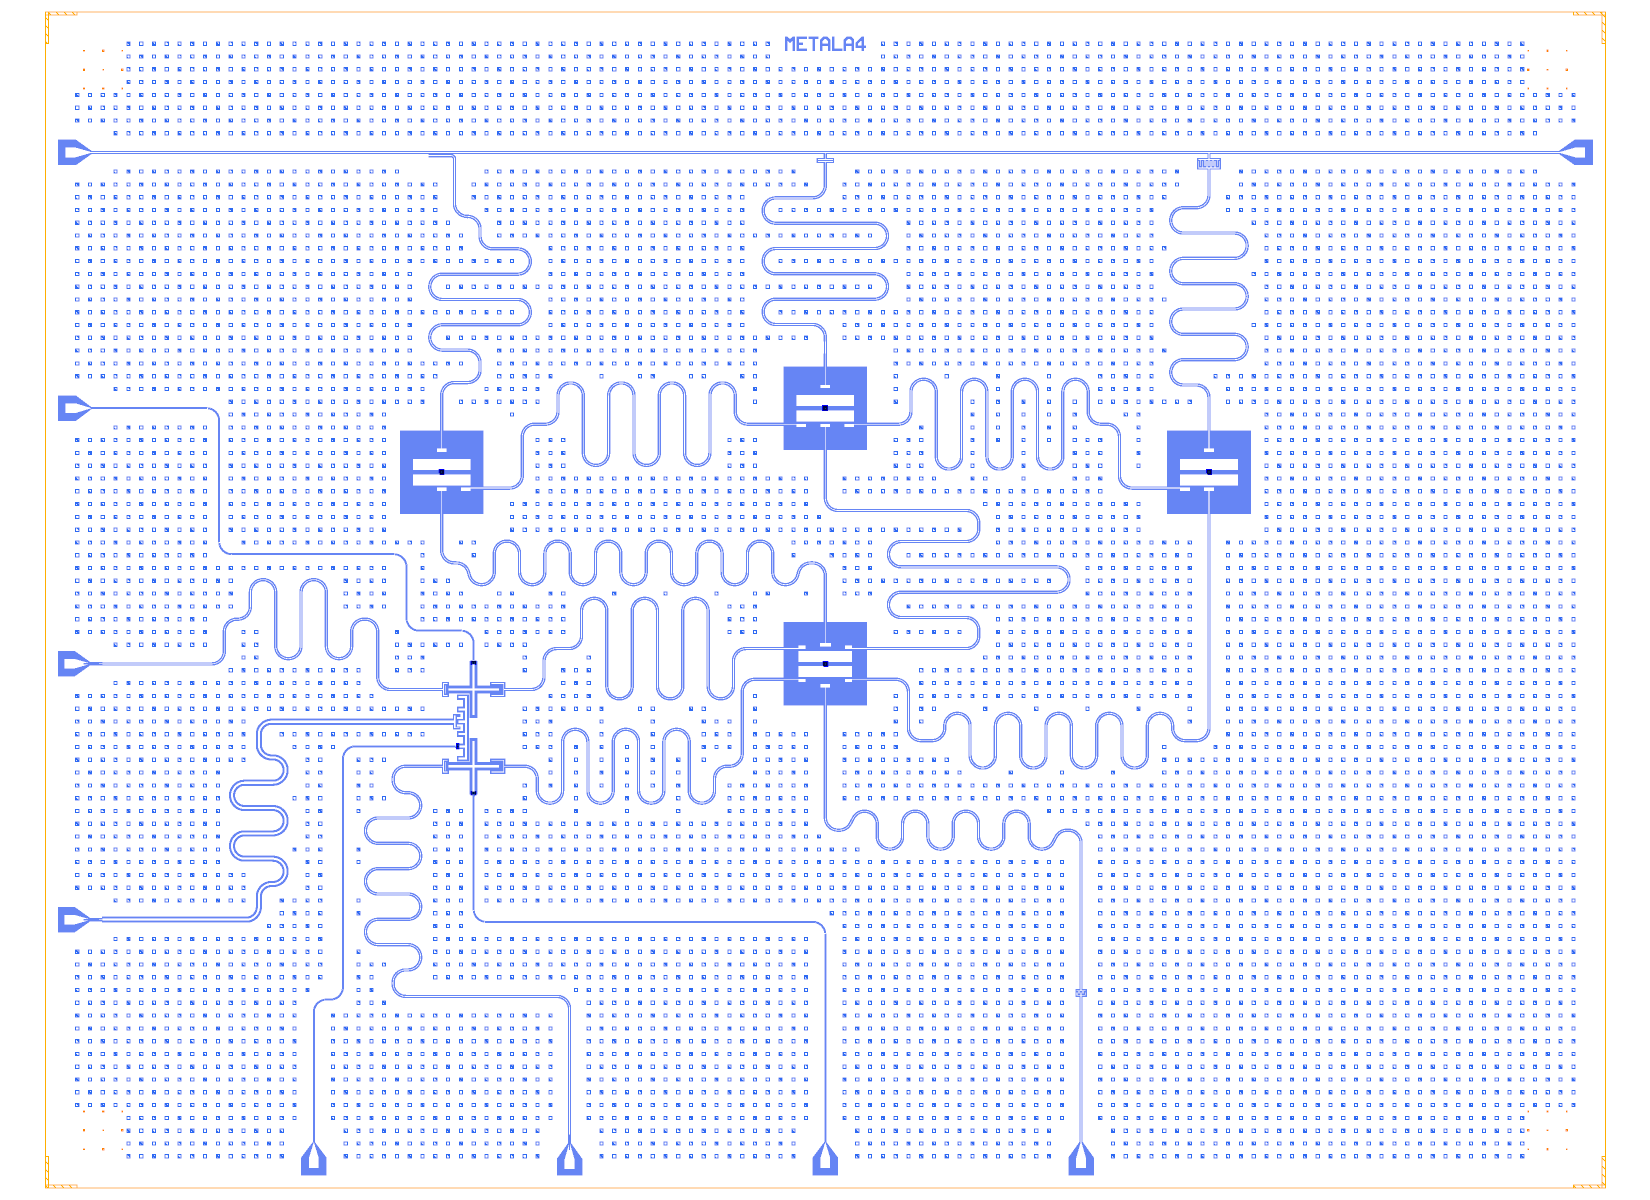

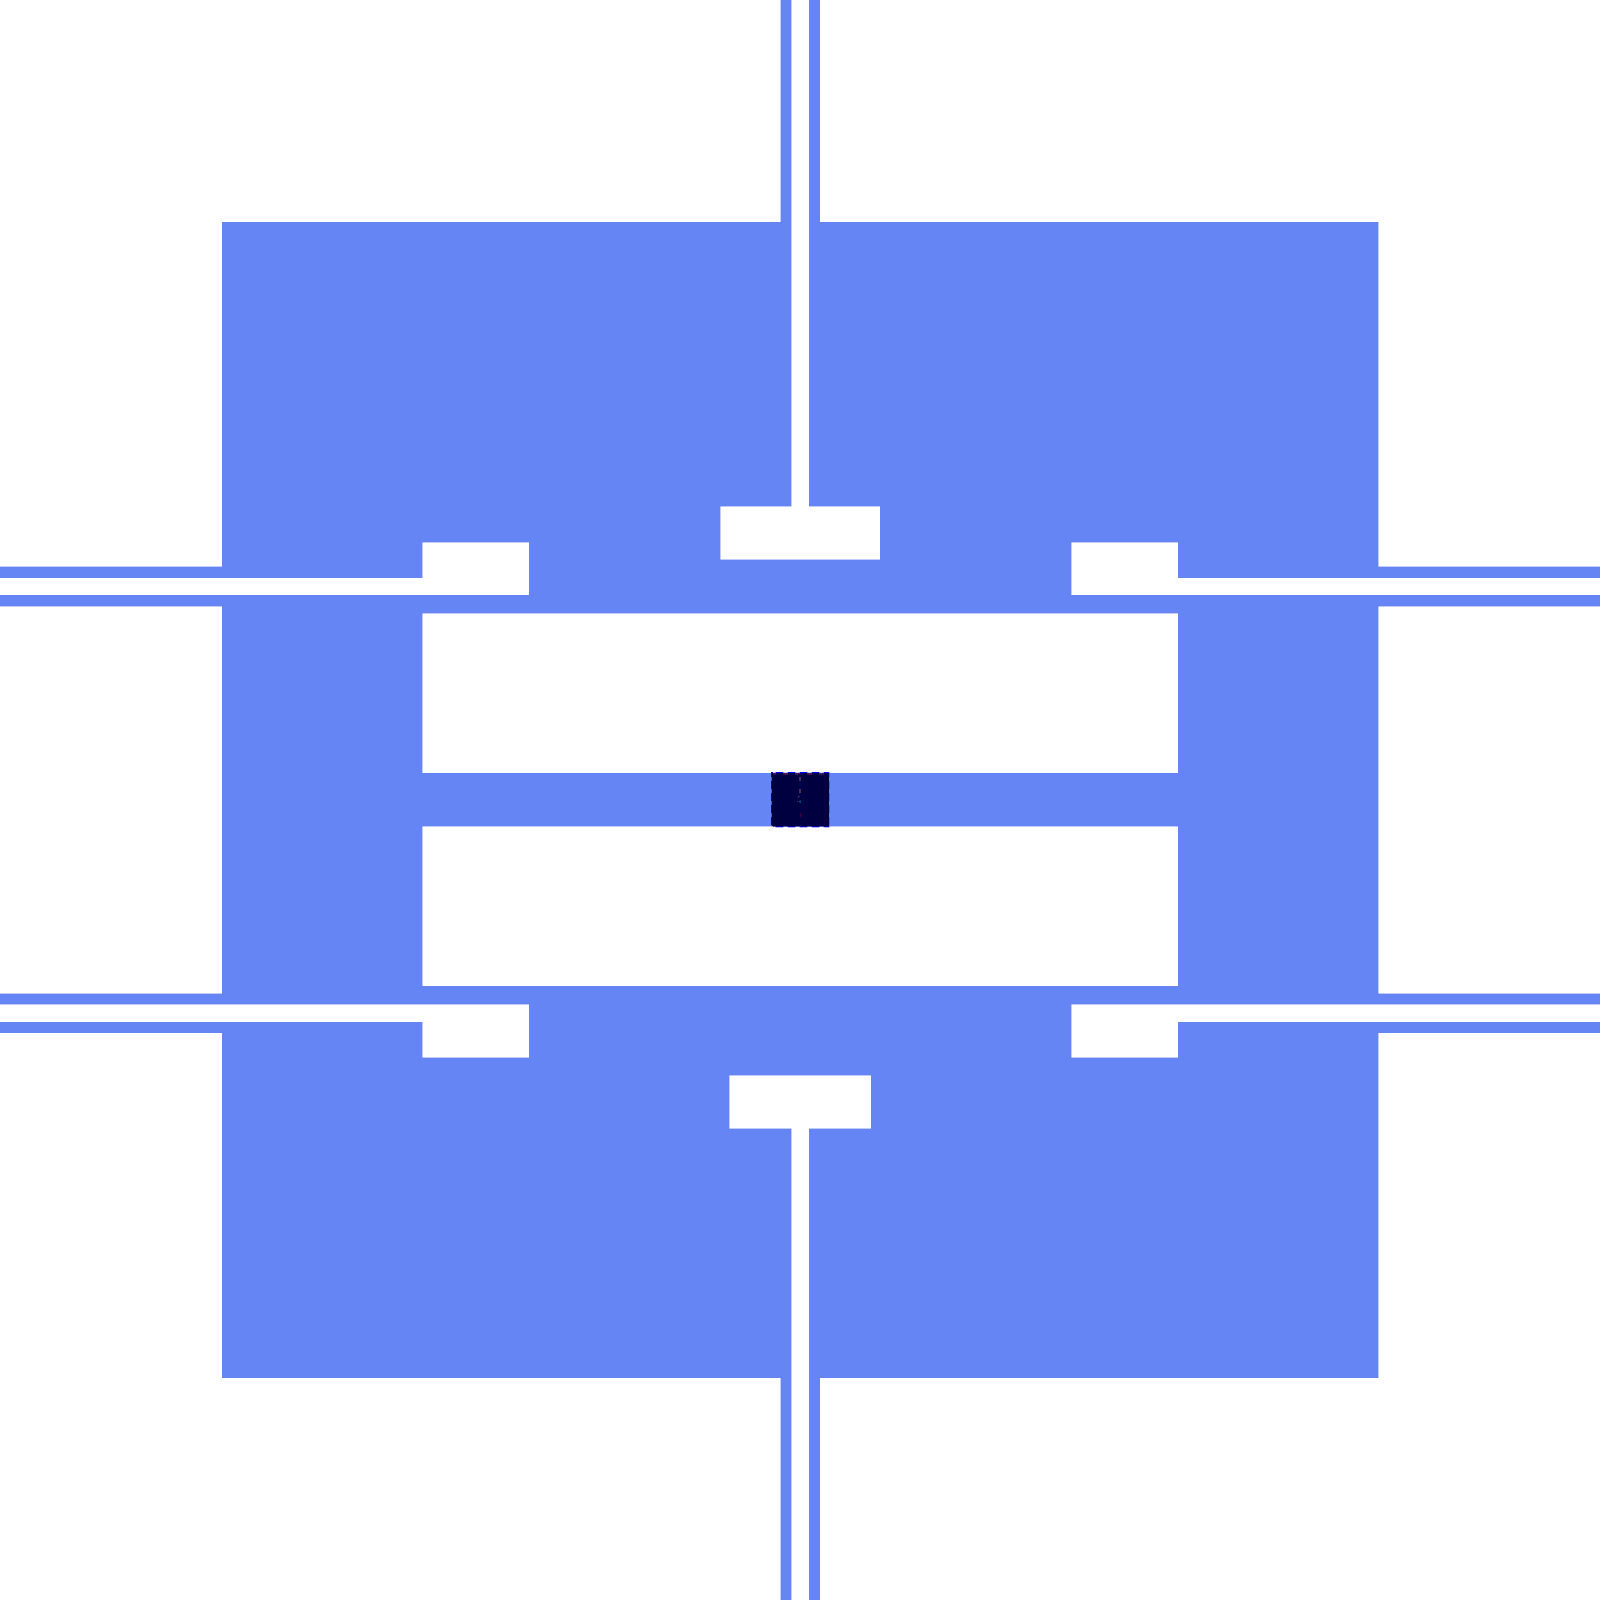

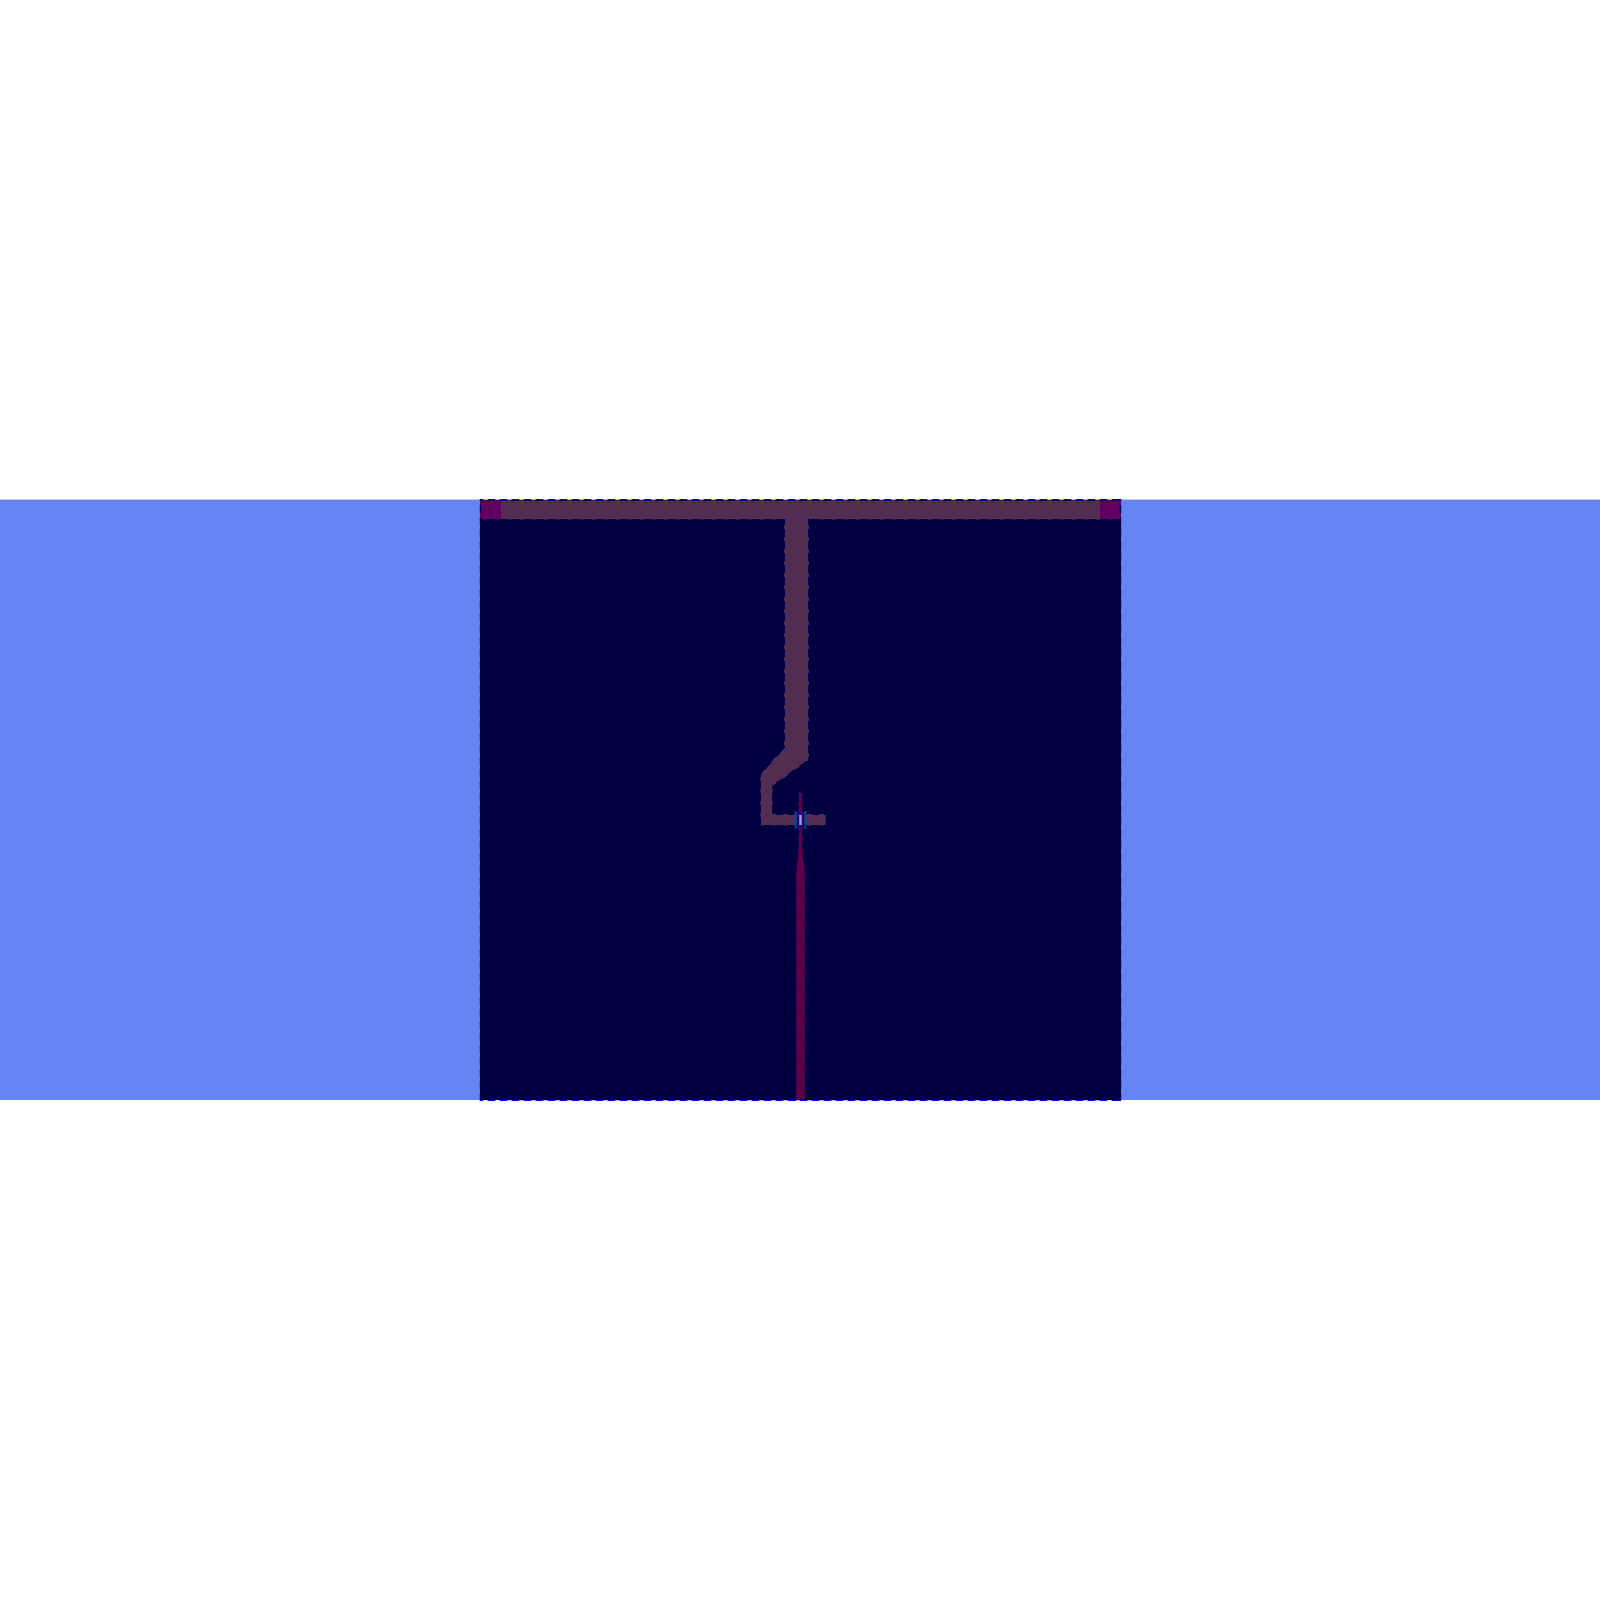

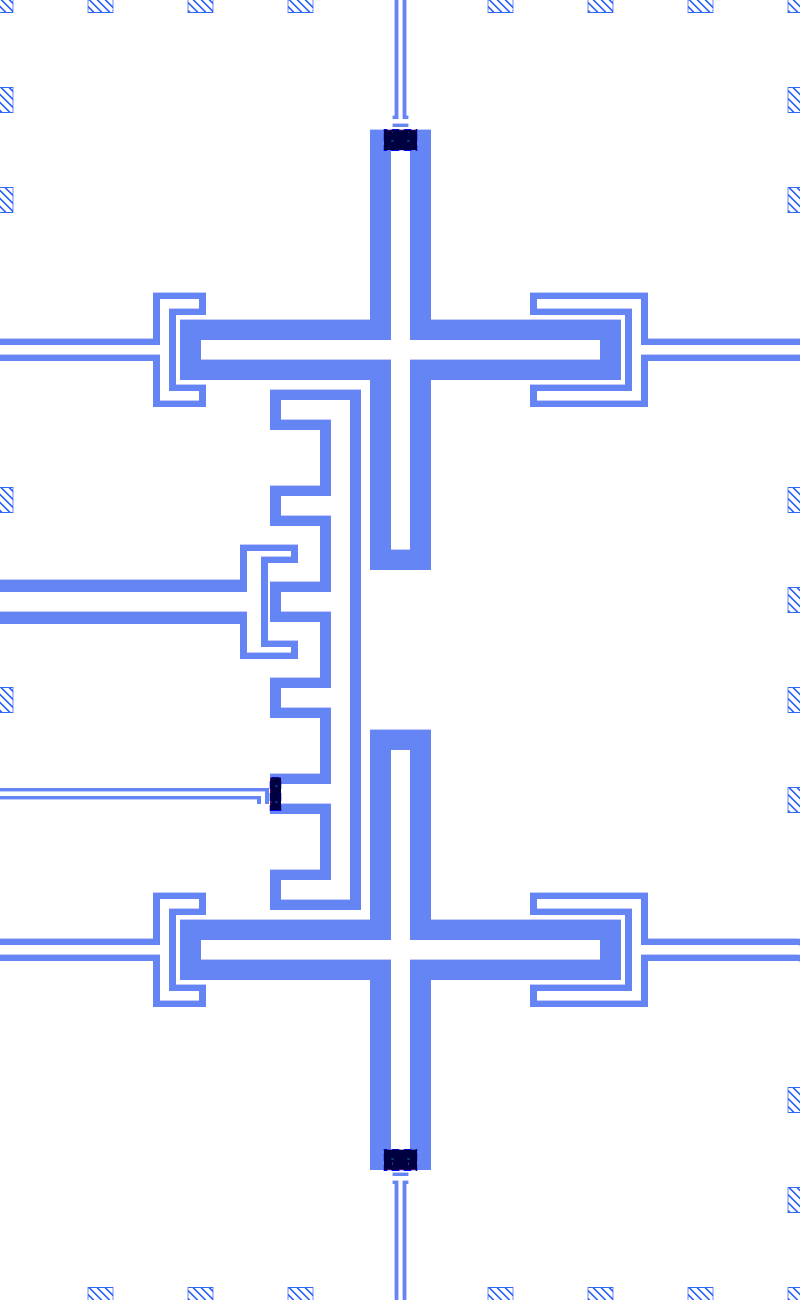

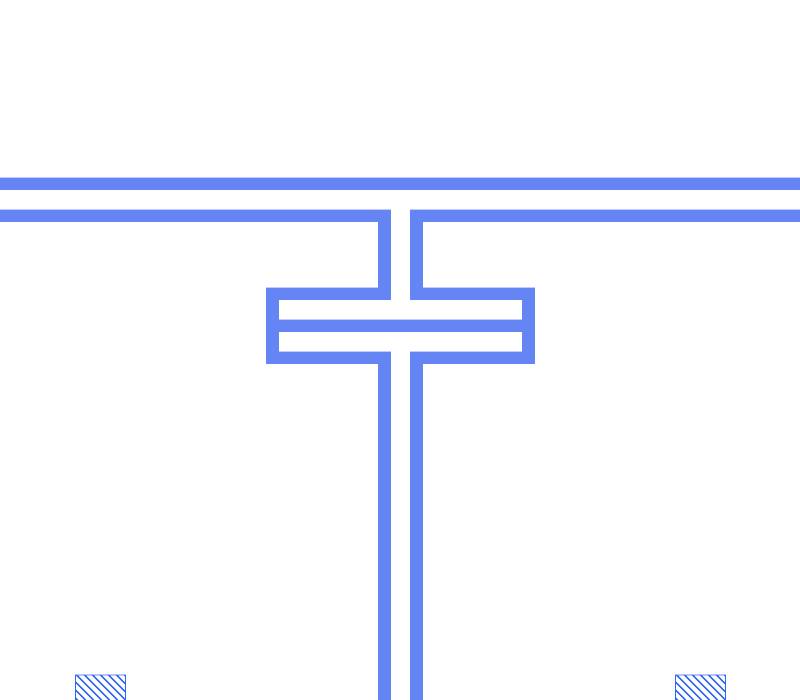

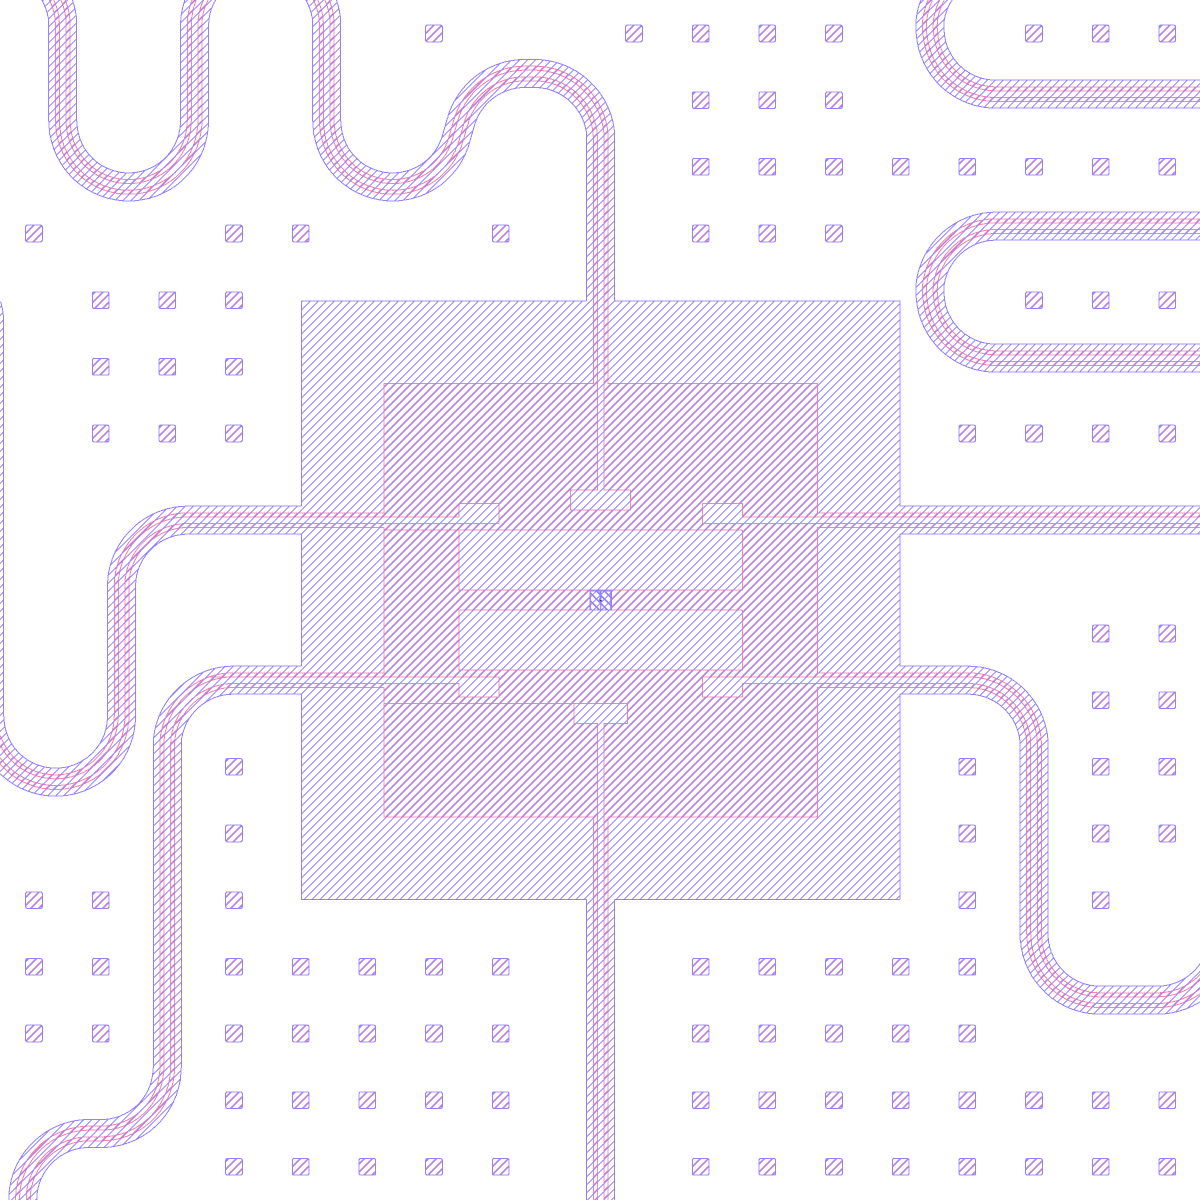

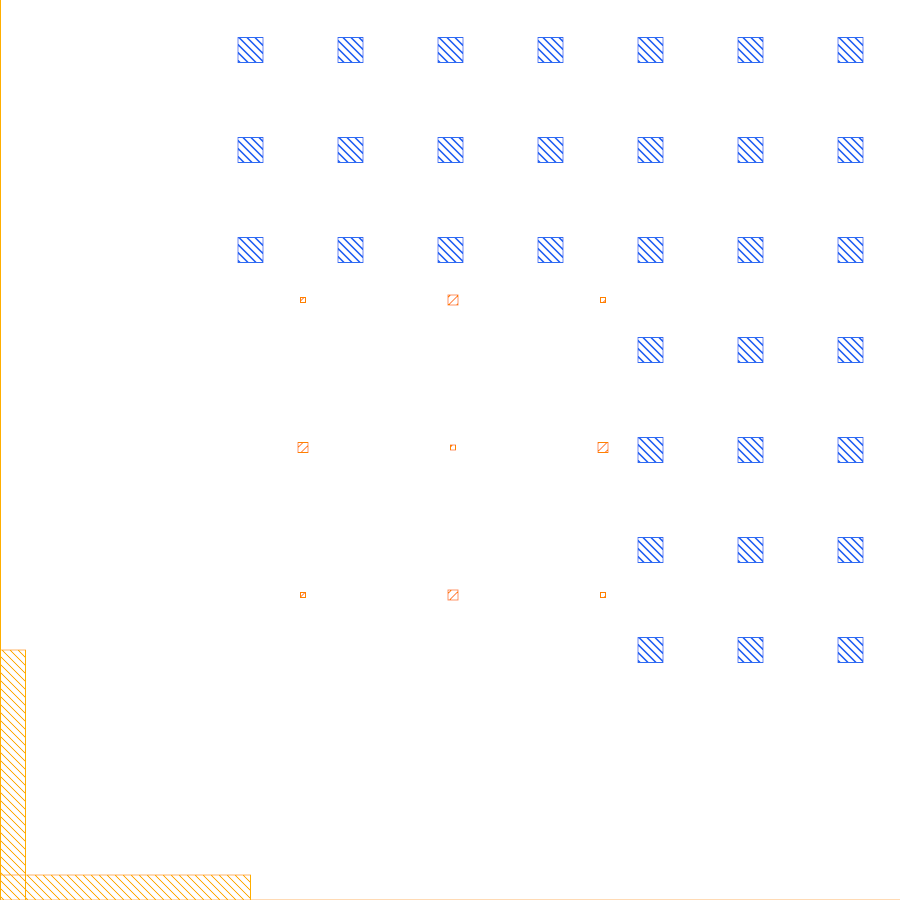

In [17]:
QX, QY = d.data["instances"]["Q_Main"]["place"]["at"]
CX, CY = d.data["instances"]["Tune_C_Q12"]["place"]["at"]
TX, TY = d.data["instances"]["Q4_Read_T"]["place"]["at"]
show_snapshot(d, OUT / "a4_full_chip.png", size=(1650, 1200))
show_snapshot(d, OUT / "a4_full_chip_qmain.png", box=(QX - 450, QY - 450, QX + 450, QY + 450), width=420)
show_snapshot(d, OUT / "a4_full_chip_jj.png", box=(QX - 40, QY - 40, QX + 40, QY + 40), width=300)
show_snapshot(d, OUT / "a4_full_chip_coupler.png", box=(CX + 60 - 400, CY - 650, CX + 60 + 400, CY + 650),
              size=(800, 1300), width=360)
show_snapshot(d, OUT / "a4_full_chip_tee.png", box=(TX - 200, TY - 250, TX + 200, TY + 100), size=(800, 700), width=360)
snap_file(Path("build") / "a4_full_chip_fab.oas", OUT / "a4_full_chip_cheese.png",
          box=(QX - 900, QY - 900, QX + 900, QY + 900), size=(1200, 1200), width=420)
show_snapshot(d, OUT / "a4_full_chip_frame.png", box=(-600, -600, 300, 300), size=(900, 900), width=300);

## 16 · Summary

| | |
|---|---|
| matches the source | every Metal component and option, their relative positions, the route end pins and total lengths (buses 6.0–7.6 mm, readouts 5.0–6.8 mm), the flux-line paths, the sim groups; the original's Metal GDS cheese (25 µm / 100 µm, 50 µm buffer) drawn by the build and kept in the mask |
| PDK changes | QCT frame on the grown 12.2 × 9.2 mm box; sapphire stack; eleven launchpads 100 µm from their edges (were 840–850 µm); trilayer junctions (Q_Main sized for 4.96 GHz, Q3–Q5 nominal, Q1 / Q2 / coupler PDK SQUIDs); content centred in x; in y pinned by the south pads and the NW / NE pads below the marker areas (offset printed in step 7, not shifted) |
| differs | the meander footprints (qcc router); the qubit frequencies move with the PDK junctions, so several buses / readouts collide with qubits (step 10); the flux lines are longer by the pad shift |
| PDK design warnings | `pdk_rn` Q_Main (≈ 98 kΩ: sized for the tutorial's 4.96 GHz; step 13 shows the PDK nominal instead) |
| open | the FEM jobs are exported, not solved (`RUN_FEM = False`) |